# BlindRobot: analysis of all SmolVLA camera-failure experiments

This notebook reads every finished rollout CSV in `results/`, puts all episodes into one table and answers four questions:

1. How noisy is the clean baseline, and what should corrupted conditions be compared with?
2. Which corruption, camera and severity hurts SmolVLA the most?
3. Does it matter *when* during the episode a camera goes dark?
4. Does the policy shift its attention to the healthy camera when the other one degrades?

Figures are saved to `figures/` (used in the README) and tables to `results/analysis/`. The notebook needs only the CSV
files and two videos from `results/`; no GPU or simulator is required.

### Setup and terms

- **Policy:** `HuggingFaceVLA/smolvla_libero`, a vision-language-action (VLA) model without fine-tuning. Its inputs are
  two camera images, the robot state and a text instruction; a flow-matching *action expert* turns them into actions.
- **Cameras:** the **main camera** (third-person view, `image`, suffix `_0`) and the **wrist camera** (`image2`, suffix `_1`).
- **Tasks:** LIBERO-Spatial tasks 0–4 ("pick up the black bowl at location X and place it on the plate"), seeds 42/43/44.
  An episode is a **success** if the task is completed within **140 policy steps** (20 Hz, 7 s).
- **Run:** one experiment batch. Each of the 7 runs re-evaluates its own 15 clean episodes (5 tasks × 3 seeds) next to
  its corrupted conditions, so every condition has 15 episodes per run.
- **Corruptions:** *blur* (Gaussian kernel size k in pixels, 256 × 256 images), *camera blackout* (black frames for the
  whole episode), *1-s blackout* (black frames for 20 steps), *reduced frame rate* (camera refreshed every P steps,
  i.e. 20/P Hz, last frame repeated in between) and *frozen first frame* (never refreshed).
- **Statistics:** success rates with 95% **Wilson** confidence intervals (CI, accurate for small n); differences in
  **percentage points (pp)**; two-sided **Fisher exact** tests on 2 × 2 success tables; **Holm** correction for
  multiple comparisons.

In [1]:
import re
from pathlib import Path

import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
TABLES = RESULTS / "analysis"
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)

# Blue = main camera and orange = wrist camera in every figure; grey = clean.
COLORS = {"main": "#2a78d6", "wrist": "#eb6834", "both": "#6250d6", "alternating": "#1baf7a", "none": "#52514e"}
INK, INK_2, INK_3, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8985", "#e4e3df", "#fcfcfb"
CLEAN_BAND = "#d9d8d3"
GREYS = LinearSegmentedColormap.from_list(
    "greys", ["#fcfcfb", "#e4e3df", "#bdbcb6", "#8a8985", "#52514e", "#2b2a28"]
)

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK_3, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 12, "axes.titlesize": 13.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "legend.frameon": False, "legend.fontsize": 11, "lines.linewidth": 2,
    "lines.markersize": 7, "errorbar.capsize": 0, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.15,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")


def pct(x):
    return f"{100 * x:.1f}%"


def show(df, formats=None):
    """Display a table with formatted columns (plain DataFrame, so reruns do not change the notebook text)."""
    out = df.copy()
    for column, fmt in (formats or {}).items():
        out[column] = [fmt.format(v) if pd.notna(v) else "" for v in out[column]]
    display(out)


def load_rollouts(path):
    df = pd.read_csv(path)
    df["success"] = df["success"].astype(str).str.lower().isin(["true", "1"])
    return df

## 0. What the corruptions look like

One clean frame from each camera (task 0, seed 42, policy step 30) with the same OpenCV operations that
`src/corruptions.py` applies. Reduced frame rate is not shown: each frame looks normal, it is only out of date.

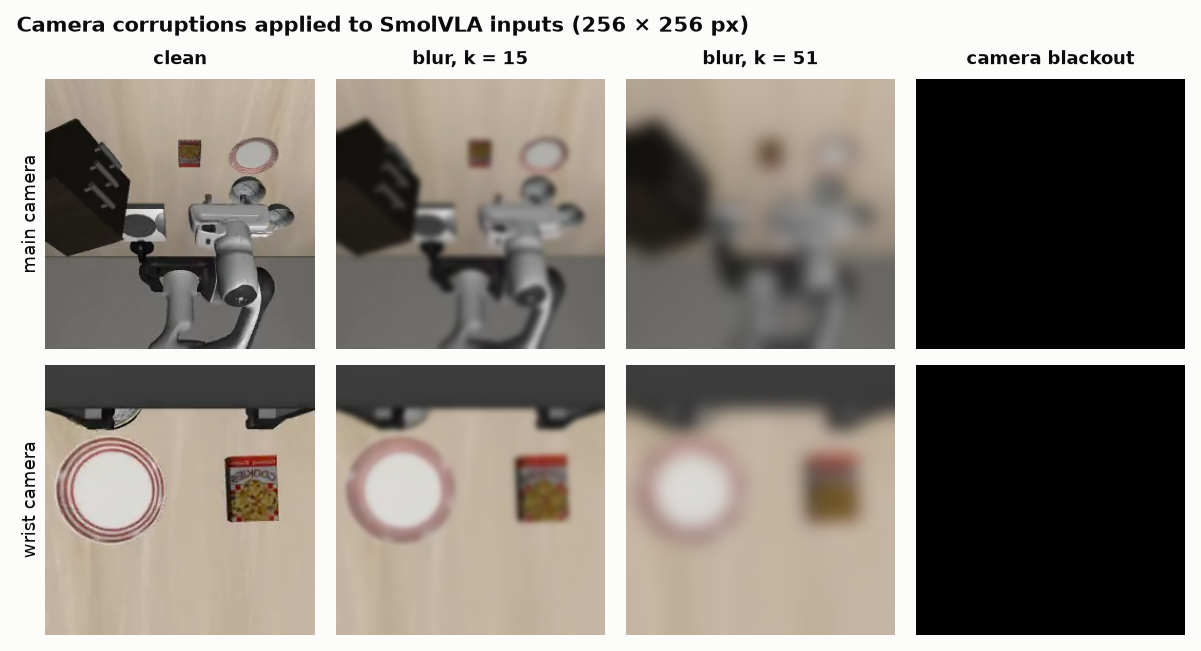

In [2]:
GALLERY_STEP = 30  # the saved videos contain one frame per policy step


def read_frame(path, step):
    capture = cv2.VideoCapture(str(path))
    capture.set(cv2.CAP_PROP_POS_FRAMES, step)
    ok, frame = capture.read()
    capture.release()
    if not ok:
        raise RuntimeError(f"cannot read {path}")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


gallery_ops = {
    "clean": lambda f: f,
    "blur, k = 15": lambda f: cv2.GaussianBlur(f, (15, 15), 0),
    "blur, k = 51": lambda f: cv2.GaussianBlur(f, (51, 51), 0),
    "camera blackout": np.zeros_like,
}
gallery_frames = {
    "main camera": read_frame(RESULTS / "videos/clean_seed42_main.mp4", GALLERY_STEP),
    "wrist camera": read_frame(RESULTS / "videos/clean_seed42_wrist.mp4", GALLERY_STEP),
}

fig, axes = plt.subplots(2, len(gallery_ops), figsize=(11, 5.8))
for row, (camera, frame) in enumerate(gallery_frames.items()):
    for col, (label, op) in enumerate(gallery_ops.items()):
        ax = axes[row, col]
        ax.imshow(op(frame))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(label, fontsize=12, loc="center")
        if col == 0:
            ax.set_ylabel(camera, fontsize=12)
fig.suptitle("Camera corruptions applied to SmolVLA inputs (256 × 256 px)", x=0.02, ha="left",
             fontweight="bold", fontsize=13.5)
fig.subplots_adjust(left=0.04, right=0.99, top=0.88, bottom=0.01, wspace=0.04, hspace=0.06)
save(fig, "corruption_examples")
plt.show()

## 1. All finished episodes in one table

The table keeps a `run` column so that every corrupted condition can also be compared with the clean episodes of
**its own run**. Not used: `results/baseline.csv`, `results/pilot.csv` and `results/visual_robustness_5tasks_3seeds.csv`
(early pilots with a 280-step limit and incomplete conditions).

In [3]:
RUNS = {  # run id -> (file, readable name)
    "blur_off_1": ("visual_robustness_5tasks_3seeds_batch.csv", "blur + blackout, run 1"),
    "blur_off_2": ("attention/rollouts_5tasks_3seeds.csv", "blur + blackout, run 2 (attention probe)"),
    "rate_main": ("freeze_image0_5tasks_3seeds.csv", "reduced frame rate, main camera"),
    "rate_wrist": ("freeze_image1_5tasks_3seeds.csv", "reduced frame rate, wrist camera"),
    "frozen": ("freeze_full_5tasks_3seeds.csv", "frozen first frame"),
    "short_off": ("temporary_off_single_5tasks_3seeds.csv", "one 1-s blackout"),
    "short_off_x3": ("temporary_off_mix_5tasks_3seeds.csv", "three 1-s blackouts"),
}
RUN_NAMES = {run: name for run, (_, name) in RUNS.items()}
CAMERA = {"0": "main", "1": "wrist"}
PHASES = {"approach": "10–29", "grasp": "40–59", "transport": "60–79"}
PHASE_ORDER = {phase: i for i, phase in enumerate(PHASES)}
POLICY_HZ = 20
MAX_STEPS = 140


def describe(condition):
    """Split a condition name into family / camera / severity level / phase."""
    info = {"family": "clean", "camera": "none", "level": np.nan, "phase": ""}
    if condition == "clean":
        return info
    if m := re.fullmatch(r"blur_(\d+)_(\d)(_\d)?", condition):
        return {**info, "family": "blur", "camera": "both" if m[3] else CAMERA[m[2]], "level": int(m[1])}
    if m := re.fullmatch(r"turnoff_(\d)", condition):
        return {**info, "family": "blackout", "camera": CAMERA[m[1]]}
    if m := re.fullmatch(r"freeze_(\d+)_(\d)", condition):
        return {**info, "family": "frame_rate", "camera": CAMERA[m[2]], "level": int(m[1])}
    if m := re.fullmatch(r"off_(approach|grasp|transport)_(\d)", condition):
        return {**info, "family": "short_blackout", "camera": CAMERA[m[2]], "phase": m[1]}
    if m := re.fullmatch(r"off_mix_(\d)_(\d)_(\d)", condition):
        return {**info, "family": "three_blackouts", "camera": "alternating",
                "phase": "→".join(CAMERA[c] for c in m.groups())}
    raise ValueError(f"unknown condition {condition!r}")


frames = []
for run, (relative_path, _) in RUNS.items():
    run_df = load_rollouts(RESULTS / relative_path)[["condition", "task_id", "seed", "success", "steps"]]
    run_df.insert(0, "run", run)
    frames.append(run_df)

episodes = pd.concat(frames, ignore_index=True)
episodes = episodes.join(pd.DataFrame([describe(c) for c in episodes["condition"]], index=episodes.index))

duplicates = episodes.duplicated(["run", "condition", "task_id", "seed"]).sum()
assert duplicates == 0, f"{duplicates} duplicated episodes"
assert episodes["steps"].le(MAX_STEPS).all()

completeness = episodes.groupby(["run", "condition"], sort=False).size().rename("episodes").reset_index()
incomplete = completeness[completeness["episodes"].ne(15)]
print(f"{len(episodes)} episodes, {episodes['condition'].nunique()} conditions, {len(RUNS)} runs")
print("Incomplete conditions (excluded from all statistics):")
display(incomplete)

INCOMPLETE = set(zip(incomplete["run"], incomplete["condition"]))
episodes["complete"] = [(r, c) not in INCOMPLETE for r, c in zip(episodes["run"], episodes["condition"])]

738 episodes, 32 conditions, 7 runs
Incomplete conditions (excluded from all statistics):


,run,condition,episodes
49,short_off_x3,off_mix_1_0_1,3


In [4]:
def summarize(df, by):
    """Success counts, 95% Wilson CI and mean episode length for each group."""
    out = (
        df.groupby(by, sort=False, dropna=False)
        .agg(successes=("success", "sum"), n=("success", "size"), mean_steps=("steps", "mean"))
        .reset_index()
    )
    out["rate"] = out["successes"] / out["n"]
    low, high = proportion_confint(out["successes"], out["n"], alpha=0.05, method="wilson")
    out["ci_low"], out["ci_high"] = np.asarray(low), np.asarray(high)
    return out


def fisher_p(k1, n1, k2, n2):
    return stats.fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1]

## 2. The clean baseline is noisy, so we pool it

The same 15 (task, seed) pairs were evaluated clean in all seven runs. LIBERO evaluation is not fully deterministic,
so the clean success rate moves between runs. A χ² test checks whether these differences are larger than sampling
noise; if not, pooling all clean episodes gives a much tighter reference than any single run.

In [5]:
clean = episodes[episodes["family"].eq("clean")]
clean_by_run = summarize(clean, ["run"])
pooled_clean = summarize(clean.assign(group="pooled"), ["group"]).iloc[0]
CLEAN_RATE, CLEAN_LOW, CLEAN_HIGH = pooled_clean[["rate", "ci_low", "ci_high"]]

chi2, chi2_p, dof, _ = stats.chi2_contingency(pd.crosstab(clean["run"], clean["success"]))
clean_by_task = summarize(clean, ["task_id"]).sort_values("task_id")
task_chi2_p = stats.chi2_contingency(pd.crosstab(clean["task_id"], clean["success"]))[1]

# How often does the same (task, seed) give different outcomes across the 7 clean runs?
outcome_per_pair = clean.groupby(["task_id", "seed"])["success"].agg(["sum", "size"])
mixed_pairs = ((outcome_per_pair["sum"] > 0) & (outcome_per_pair["sum"] < outcome_per_pair["size"])).sum()

show(clean_by_run.assign(run=clean_by_run["run"].map(RUN_NAMES))[["run", "successes", "n", "rate", "ci_low", "ci_high"]],
     {"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"})
print(f"Pooled clean: {pooled_clean.successes}/{pooled_clean.n} = {pct(CLEAN_RATE)} "
      f"(95% CI {pct(CLEAN_LOW)}–{pct(CLEAN_HIGH)})")
print(f"Differences between runs: chi2={chi2:.2f}, dof={dof}, p={chi2_p:.3f}  -> no evidence of run differences")
print(f"Differences between tasks: p={task_chi2_p:.1e}")
print(f"(task, seed) pairs with both successes and failures across runs: {mixed_pairs}/{len(outcome_per_pair)}")

,run,successes,n,rate,ci_low,ci_high
0,"blur + blackout, run 1",11,15,73.3%,48.0%,89.1%
1,"blur + blackout, run 2 (attention probe)",12,15,80.0%,54.8%,93.0%
2,"reduced frame rate, main camera",10,15,66.7%,41.7%,84.8%
3,"reduced frame rate, wrist camera",11,15,73.3%,48.0%,89.1%
4,frozen first frame,8,15,53.3%,30.1%,75.2%
5,one 1-s blackout,13,15,86.7%,62.1%,96.3%
6,three 1-s blackouts,8,15,53.3%,30.1%,75.2%


Pooled clean: 73/105 = 69.5% (95% CI 60.2%–77.5%)
Differences between runs: chi2=6.83, dof=6, p=0.337  -> no evidence of run differences
Differences between tasks: p=4.1e-05
(task, seed) pairs with both successes and failures across runs: 10/15


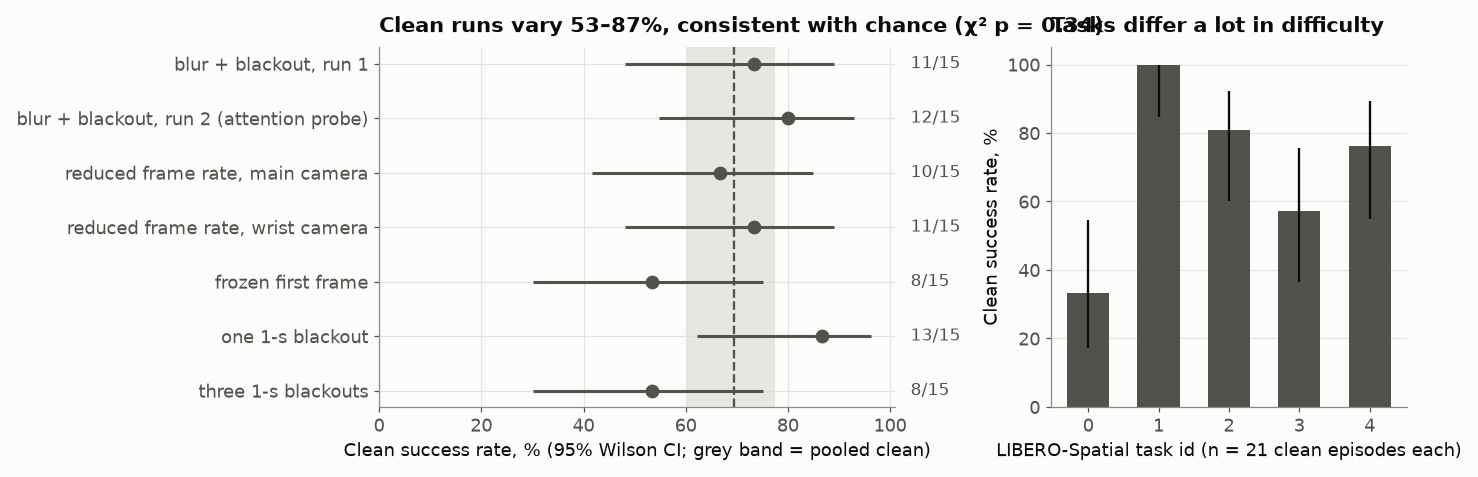

In [6]:
fig, (ax_run, ax_task) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.45, 1]})

ax_run.axvspan(100 * CLEAN_LOW, 100 * CLEAN_HIGH, color=CLEAN_BAND, alpha=0.6, lw=0)
ax_run.axvline(100 * CLEAN_RATE, color=INK_2, lw=1.5, ls="--")
y = np.arange(len(clean_by_run))[::-1]
ax_run.errorbar(100 * clean_by_run["rate"], y,
                xerr=[100 * (clean_by_run["rate"] - clean_by_run["ci_low"]), 100 * (clean_by_run["ci_high"] - clean_by_run["rate"])],
                fmt="o", color=COLORS["none"], ms=8, elinewidth=2)
for yi, row in zip(y, clean_by_run.itertuples()):
    ax_run.text(104, yi, f"{row.successes}/{row.n}", va="center", fontsize=11, color=INK_2, clip_on=False)
ax_run.set_yticks(y, clean_by_run["run"].map(RUN_NAMES))
ax_run.set_xlim(0, 101)
ax_run.set_xlabel("Clean success rate, % (95% Wilson CI; grey band = pooled clean)")
ax_run.set_title(f"Clean runs vary {100 * clean_by_run['rate'].min():.0f}–{100 * clean_by_run['rate'].max():.0f}%, "
                 f"{'consistent with chance' if chi2_p >= 0.05 else 'more than chance'} (χ² p = {chi2_p:.2f})")

ax_task.bar(clean_by_task["task_id"], 100 * clean_by_task["rate"], color=COLORS["none"], width=0.6)
ax_task.errorbar(clean_by_task["task_id"], 100 * clean_by_task["rate"],
                 yerr=[100 * (clean_by_task["rate"] - clean_by_task["ci_low"]), 100 * (clean_by_task["ci_high"] - clean_by_task["rate"])],
                 fmt="none", color=INK, elinewidth=1.5)
ax_task.set_ylim(0, 105)
ax_task.set_xlabel("LIBERO-Spatial task id (n = 21 clean episodes each)")
ax_task.set_ylabel("Clean success rate, %")
ax_task.set_title("Tasks differ a lot in difficulty")
ax_task.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "clean_baseline")
plt.show()

## 3. Every condition against clean

Two references are used:

- **Same-run clean** (15 episodes): immune to drift between runs, but noisy. Holm correction is applied over all
  corrupted conditions of all runs (42 tests).
- **Pooled clean** (105 episodes): the χ² test above found no evidence of run differences, so this is the main
  reference in the overview figure and the README. Holm correction is applied over the 30 pooled conditions.

Holm controls the chance of any false positive across the whole family of tests. With 15 episodes per condition one
success shifts the rate by 6.7 pp, so only large drops survive the correction.

In [7]:
by_run = summarize(episodes[episodes["complete"]], ["run", "condition", "family", "camera", "level", "phase"])
clean_ref = by_run[by_run["family"].eq("clean")].set_index("run")[["successes", "n", "rate"]].add_prefix("clean_")
by_run = by_run.join(clean_ref, on="run")
corrupted = by_run[by_run["family"].ne("clean")].copy()
corrupted["delta_pp"] = 100 * (corrupted["rate"] - corrupted["clean_rate"])
corrupted["p_fisher"] = [
    fisher_p(r.successes, r.n, r.clean_successes, r.clean_n) for r in corrupted.itertuples()
]
corrupted["p_holm"] = multipletests(corrupted["p_fisher"], method="holm")[1]
print(f"Holm family vs same-run clean: {len(corrupted)} tests")

same_run_table = corrupted[["run", "condition", "successes", "n", "rate", "clean_rate", "delta_pp", "p_fisher", "p_holm"]]
same_run_table.to_csv(TABLES / "conditions_vs_same_run_clean.csv", index=False)
show(same_run_table, {"rate": "{:.1%}", "clean_rate": "{:.1%}", "delta_pp": "{:+.1f}",
                      "p_fisher": "{:.3f}", "p_holm": "{:.3f}"})

Holm family vs same-run clean: 42 tests


,run,condition,successes,n,rate,clean_rate,delta_pp,p_fisher,p_holm
1,blur_off_1,blur_5_0,6,15,40.0%,73.3%,-33.3,0.139,1.000
2,blur_off_1,blur_11_0,11,15,73.3%,73.3%,+0.0,1.000,1.000
3,blur_off_1,blur_15_0,5,15,33.3%,73.3%,-40.0,0.066,1.000
4,blur_off_1,blur_31_0,3,15,20.0%,73.3%,-53.3,0.009,0.295
5,blur_off_1,blur_51_0,3,15,20.0%,73.3%,-53.3,0.009,0.295
6,blur_off_1,blur_5_1,11,15,73.3%,73.3%,+0.0,1.000,1.000
7,blur_off_1,blur_11_1,8,15,53.3%,73.3%,-20.0,0.450,1.000
8,blur_off_1,blur_15_1,7,15,46.7%,73.3%,-26.7,0.264,1.000
9,blur_off_1,blur_31_1,8,15,53.3%,73.3%,-20.0,0.450,1.000
10,blur_off_1,blur_51_1,2,15,13.3%,73.3%,-60.0,0.003,0.088


### Can the two blur + blackout runs be pooled?

Blur and whole-episode blackout were evaluated twice. If the two runs agree, pooling gives 30 episodes per condition.
Note that the 30 episodes are the same 15 (task, seed) starts evaluated twice.

In [8]:
two_runs = by_run[by_run["run"].isin(["blur_off_1", "blur_off_2"])].pivot(
    index="condition", columns="run", values="successes").dropna()
two_runs["p_fisher_run1_vs_run2"] = [fisher_p(r.blur_off_1, 15, r.blur_off_2, 15) for r in two_runs.itertuples()]
show(two_runs.reset_index(), {"p_fisher_run1_vs_run2": "{:.2f}"})
print(f"Smallest p between the two runs: {two_runs['p_fisher_run1_vs_run2'].min():.2f}  -> runs agree, pool them")

run,condition,blur_off_1,blur_off_2,p_fisher_run1_vs_run2
0,blur_11_0,11.0,9.0,0.70
1,blur_11_1,8.0,9.0,1.00
2,blur_15_0,5.0,4.0,1.00
3,blur_15_1,7.0,7.0,1.00
4,blur_31_0,3.0,4.0,1.00
5,blur_31_1,8.0,7.0,1.00
6,blur_51_0,3.0,2.0,1.00
7,blur_51_1,2.0,3.0,1.00
8,blur_5_0,6.0,8.0,0.72
9,blur_5_1,11.0,8.0,0.45


Smallest p between the two runs: 0.45  -> runs agree, pool them


### Pooled view

In [9]:
pooled = summarize(
    episodes[episodes["complete"] & episodes["family"].ne("clean")],
    ["condition", "family", "camera", "level", "phase"],
)
pooled["delta_pp"] = 100 * (pooled["rate"] - CLEAN_RATE)
pooled["p_vs_pooled_clean"] = [
    fisher_p(r.successes, r.n, pooled_clean.successes, pooled_clean.n) for r in pooled.itertuples()
]
pooled["p_holm"] = multipletests(pooled["p_vs_pooled_clean"], method="holm")[1]
print(f"Holm family vs pooled clean: {len(pooled)} tests")
pooled.to_csv(TABLES / "conditions_vs_pooled_clean.csv", index=False)

significant = pooled[pooled["p_holm"] < 0.05]
not_significant = pooled[pooled["p_holm"] >= 0.05]
print(f"Significant after Holm: {len(significant)}/{len(pooled)} conditions; "
      f"smallest significant drop {-significant['delta_pp'].max():.1f} pp, "
      f"largest non-significant drop {-not_significant['delta_pp'].min():.1f} pp")

Holm family vs pooled clean: 30 tests
Significant after Holm: 9/30 conditions; smallest significant drop 39.5 pp, largest non-significant drop 42.9 pp


In [10]:
def label(row):
    if row.family == "blur":
        return f"k = {int(row.level)}"
    if row.family == "blackout":
        return f"{row.camera} camera"
    if row.family == "frame_rate":
        return "frozen first frame" if row.level >= MAX_STEPS else f"{POLICY_HZ / row.level:g} Hz (every {int(row.level)} steps)"
    if row.family == "short_blackout":
        return f"{row.phase}, steps {PHASES[row.phase]}"
    return row.phase


GROUPS = [  # (header, row filter, sort key)
    ("Blur · main camera", lambda d: d.family.eq("blur") & d.camera.eq("main"), "level"),
    ("Blur · wrist camera", lambda d: d.family.eq("blur") & d.camera.eq("wrist"), "level"),
    ("Blur · both cameras", lambda d: d.family.eq("blur") & d.camera.eq("both"), "level"),
    ("Camera blackout, whole episode", lambda d: d.family.eq("blackout"), "camera"),
    ("Reduced frame rate · main camera", lambda d: d.family.eq("frame_rate") & d.camera.eq("main"), "level"),
    ("Reduced frame rate · wrist camera", lambda d: d.family.eq("frame_rate") & d.camera.eq("wrist"), "level"),
    ("1-s blackout · main camera", lambda d: d.family.eq("short_blackout") & d.camera.eq("main"), "phase_order"),
    ("1-s blackout · wrist camera", lambda d: d.family.eq("short_blackout") & d.camera.eq("wrist"), "phase_order"),
    ("Three 1-s blackouts", lambda d: d.family.eq("three_blackouts"), "phase"),
]
pooled["label"] = [label(r) for r in pooled.itertuples()]
pooled["phase_order"] = pooled["phase"].map(PHASE_ORDER)
ordered = pd.concat(
    [pooled[mask(pooled)].sort_values(key).assign(group=group) for group, mask, key in GROUPS],
    ignore_index=True,
)

show(ordered[["group", "label", "condition", "successes", "n", "rate", "ci_low", "ci_high", "delta_pp", "p_holm"]],
     {"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}", "delta_pp": "{:+.1f}", "p_holm": "{:.3f}"})

,group,label,condition,successes,n,rate,ci_low,ci_high,delta_pp,p_holm
0,Blur · main camera,k = 5,blur_5_0,14,30,46.7%,30.2%,63.9%,-22.9,0.569
1,Blur · main camera,k = 11,blur_11_0,20,30,66.7%,48.8%,80.8%,-2.9,1.000
2,Blur · main camera,k = 15,blur_15_0,9,30,30.0%,16.7%,47.9%,-39.5,0.005
3,Blur · main camera,k = 31,blur_31_0,7,30,23.3%,11.8%,40.9%,-46.2,0.000
4,Blur · main camera,k = 51,blur_51_0,5,30,16.7%,7.3%,33.6%,-52.9,0.000
5,Blur · wrist camera,k = 5,blur_5_1,19,30,63.3%,45.5%,78.1%,-6.2,1.000
6,Blur · wrist camera,k = 11,blur_11_1,17,30,56.7%,39.2%,72.6%,-12.9,1.000
7,Blur · wrist camera,k = 15,blur_15_1,14,30,46.7%,30.2%,63.9%,-22.9,0.569
8,Blur · wrist camera,k = 31,blur_31_1,15,30,50.0%,33.2%,66.8%,-19.5,0.862
9,Blur · wrist camera,k = 51,blur_51_1,5,30,16.7%,7.3%,33.6%,-52.9,0.000


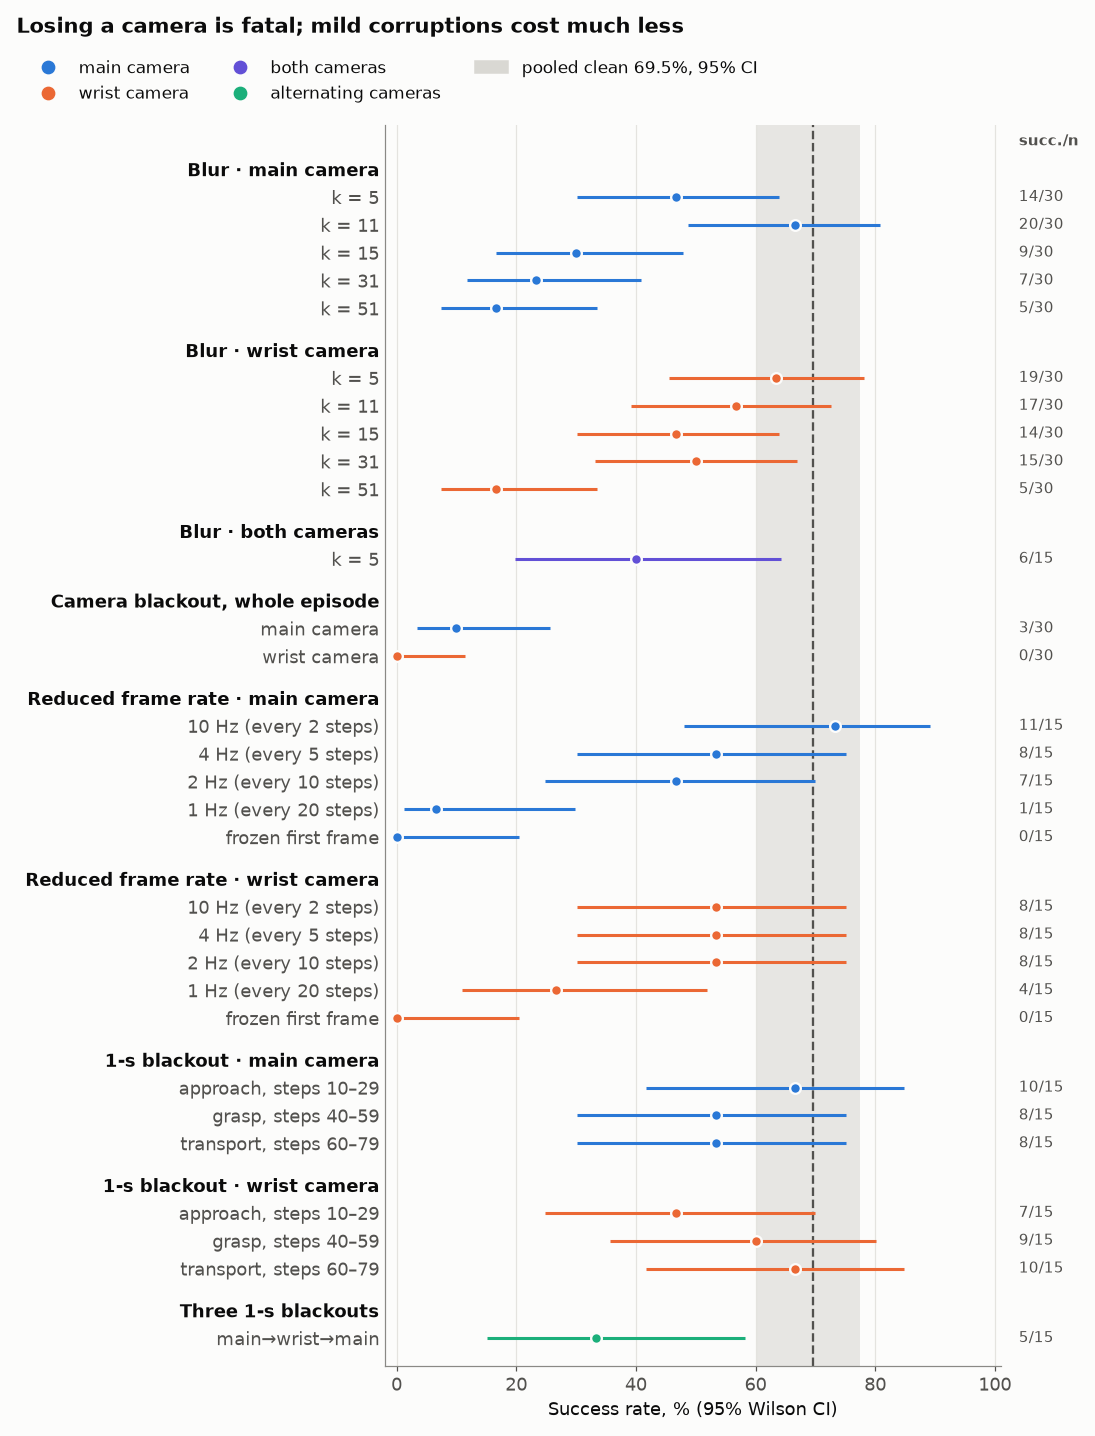

In [11]:
CAMERA_LABELS = {"main": "main camera", "wrist": "wrist camera", "both": "both cameras",
                 "alternating": "alternating cameras"}


def forest(ax, table):
    """Dot + CI per condition, grouped under bold headers, pooled clean band behind."""
    ticks, labels, bold, positions = [], [], [], {}
    y = 0
    for group, part in table.groupby("group", sort=False):
        ticks.append(y)
        labels.append(group)
        bold.append(True)
        y -= 1
        for row in part.itertuples():
            positions[row.Index] = y
            ticks.append(y)
            labels.append(row.label)
            bold.append(False)
            y -= 1
        y -= 0.5

    ax.axvspan(100 * CLEAN_LOW, 100 * CLEAN_HIGH, color=CLEAN_BAND, alpha=0.6, lw=0)
    ax.axvline(100 * CLEAN_RATE, color=INK_2, lw=1.5, ls="--")
    for camera, part in table.groupby("camera"):
        ys = [positions[i] for i in part.index]
        ax.errorbar(100 * part["rate"], ys,
                    xerr=[100 * (part["rate"] - part["ci_low"]), 100 * (part["ci_high"] - part["rate"])],
                    fmt="o", ms=7, elinewidth=2, color=COLORS[camera],
                    markeredgecolor=SURFACE, markeredgewidth=1.5, clip_on=False, zorder=3)
    ax.text(104, 1.0, "succ./n", va="center", fontsize=10, color=INK_2, fontweight="bold", clip_on=False)
    for i, row in table.iterrows():
        ax.text(104, positions[i], f"{row.successes}/{row.n}", va="center", fontsize=10, color=INK_2, clip_on=False)
    ax.set_yticks(ticks, labels)
    for tick, is_bold in zip(ax.get_yticklabels(), bold):
        if is_bold:
            tick.set_fontweight("bold")
            tick.set_color(INK)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(-2, 101)
    ax.set_ylim(y + 0.5, 1.6)
    ax.set_xticks(range(0, 101, 20))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Success rate, % (95% Wilson CI)")


fig, ax = plt.subplots(figsize=(10, 13))
forest(ax, ordered)
legend_items = [
    Line2D([], [], marker="o", ls="", ms=8, color=COLORS[c], label=CAMERA_LABELS[c])
    for c in ["main", "wrist", "both", "alternating"]
] + [Patch(color=CLEAN_BAND, label=f"pooled clean {pct(CLEAN_RATE)}, 95% CI")]
fig.suptitle("Losing a camera is fatal; mild corruptions cost much less",
             x=0.01, ha="left", y=0.995, fontweight="bold", fontsize=14)
fig.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(0.01, 0.975), ncol=3, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.962))
save(fig, "overview_success")
plt.show()

## 4. Severity curves: blur strength and camera frame rate

Left: the blur kernel grows from left to right; whole-episode blackout is shown as the extreme end of the scale
(dotted). Right: the camera is refreshed every *P* policy steps (20/*P* Hz); "frozen" means only the very first frame
is ever shown. The x axes are ordinal (equally spaced categories), so the connecting lines only guide the eye.

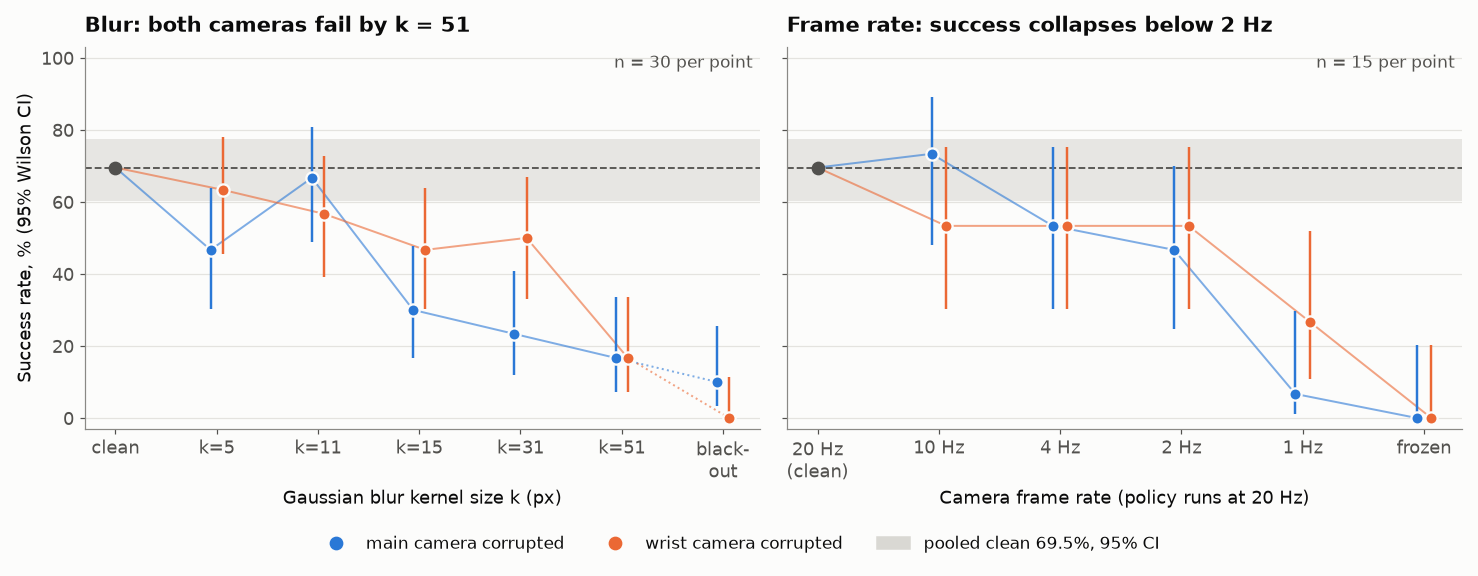

In [12]:
def curve_points(camera, family, levels, extra=None):
    part = pooled[pooled["family"].eq(family) & pooled["camera"].eq(camera)].set_index("level")
    rows = [part.loc[level] for level in levels]
    if extra is not None:
        rows.append(pooled[pooled["condition"].eq(extra)].iloc[0])
    return pd.DataFrame(rows)


BLUR_LEVELS = [5, 11, 15, 31, 51]
RATE_LEVELS = [2, 5, 10, 20, 140]
fig, (ax_blur, ax_rate) = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)

panels = [
    (ax_blur, "blur", BLUR_LEVELS, {"main": "turnoff_0", "wrist": "turnoff_1"},
     ["clean"] + [f"k={k}" for k in BLUR_LEVELS] + ["black-\nout"], "Gaussian blur kernel size k (px)",
     "Blur: both cameras fail by k = 51", "n = 30 per point"),
    (ax_rate, "frame_rate", RATE_LEVELS, None,
     ["20 Hz\n(clean)", "10 Hz", "4 Hz", "2 Hz", "1 Hz", "frozen"], "Camera frame rate (policy runs at 20 Hz)",
     "Frame rate: success collapses below 2 Hz", "n = 15 per point"),
]
for ax, family, levels, extras, ticklabels, xlabel, title, note in panels:
    ax.axhspan(100 * CLEAN_LOW, 100 * CLEAN_HIGH, color=CLEAN_BAND, alpha=0.6, lw=0)
    ax.axhline(100 * CLEAN_RATE, color=INK_2, lw=1.2, ls="--")
    for camera, offset in [("main", -0.06), ("wrist", 0.06)]:
        pts = curve_points(camera, family, levels, extras[camera] if extras else None)
        x = np.arange(1, len(pts) + 1) + offset
        rate = 100 * pts["rate"].to_numpy(float)
        err = [rate - 100 * pts["ci_low"].to_numpy(float), 100 * pts["ci_high"].to_numpy(float) - rate]
        x_line = np.r_[0, x]
        y_line = np.r_[100 * CLEAN_RATE, rate]
        solid = len(levels) + 1
        ax.plot(x_line[:solid], y_line[:solid], color=COLORS[camera], lw=1.3, alpha=0.6)
        if extras:
            ax.plot(x_line[solid - 1:], y_line[solid - 1:], color=COLORS[camera], lw=1.3, alpha=0.6, ls=":")
        ax.errorbar(x, rate, yerr=err, fmt="o", color=COLORS[camera], ms=8, elinewidth=1.6,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, clip_on=False, zorder=3)
    ax.plot([0], [100 * CLEAN_RATE], "o", color=COLORS["none"], ms=8, zorder=3)
    ax.set_xticks(range(len(ticklabels)), ticklabels)
    ax.set_xlabel(xlabel)
    ax.set_ylim(-3, 103)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.text(0.99, 0.98, note, transform=ax.transAxes, ha="right", va="top", fontsize=11, color=INK_2)
ax_blur.set_ylabel("Success rate, % (95% Wilson CI)")
legend_items = [
    Line2D([], [], marker="o", ls="", ms=8, color=COLORS["main"], label="main camera corrupted"),
    Line2D([], [], marker="o", ls="", ms=8, color=COLORS["wrist"], label="wrist camera corrupted"),
    Patch(color=CLEAN_BAND, label=f"pooled clean {pct(CLEAN_RATE)}, 95% CI"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.07, 1, 1))
save(fig, "severity_curves")
plt.show()

### Main vs wrist camera at equal severity

Within each corruption family both cameras get the same severities. A Cochran–Mantel–Haenszel (CMH) test compares
the two cameras while stratifying by severity (or phase); whole-episode blackout has a single stratum, so it uses
Fisher's test. These p-values are not corrected for multiple comparisons. Frame-rate conditions for the two cameras
come from different runs, so that comparison also contains run-to-run noise.

In [13]:
rows = []
for family, key in [("blur", "level"), ("frame_rate", "level"), ("blackout", None), ("short_blackout", "phase")]:
    part = episodes[episodes["complete"] & episodes["family"].eq(family) & episodes["camera"].isin(["main", "wrist"])]
    counts = part.groupby("camera")["success"].agg(["sum", "size"])
    if key is None:
        p = fisher_p(counts.loc["main", "sum"], counts.loc["main", "size"], counts.loc["wrist", "sum"], counts.loc["wrist", "size"])
        test = "Fisher"
    else:
        tables = [
            pd.crosstab(s["camera"], s["success"]).reindex(index=["main", "wrist"], columns=[True, False], fill_value=0).to_numpy()
            for _, s in part.groupby(key)
        ]
        p = StratifiedTable(tables).test_null_odds(correction=True).pvalue
        test = "CMH"
    rows.append({"family": family, "main": f"{counts.loc['main', 'sum']}/{counts.loc['main', 'size']}",
                 "wrist": f"{counts.loc['wrist', 'sum']}/{counts.loc['wrist', 'size']}", "test": test, "p": p})
camera_compare = pd.DataFrame(rows)
show(camera_compare, {"p": "{:.3f}"})

,family,main,wrist,test,p
0,blur,55/150,70/150,CMH,0.086
1,frame_rate,27/75,28/75,CMH,1.000
2,blackout,3/30,0/30,Fisher,0.237
3,short_blackout,26/45,26/45,CMH,0.834


## 5. Does the timing of a 1-s blackout matter?

One camera goes black for 20 policy steps (1 s) during approach (steps 10–29), grasp (40–59) or transport (60–79).
The phase boundaries are approximate because episodes differ in length. The figure shows both references: the clean
episodes of the same run (which happened to be the best of all seven clean runs) and the pooled clean baseline.

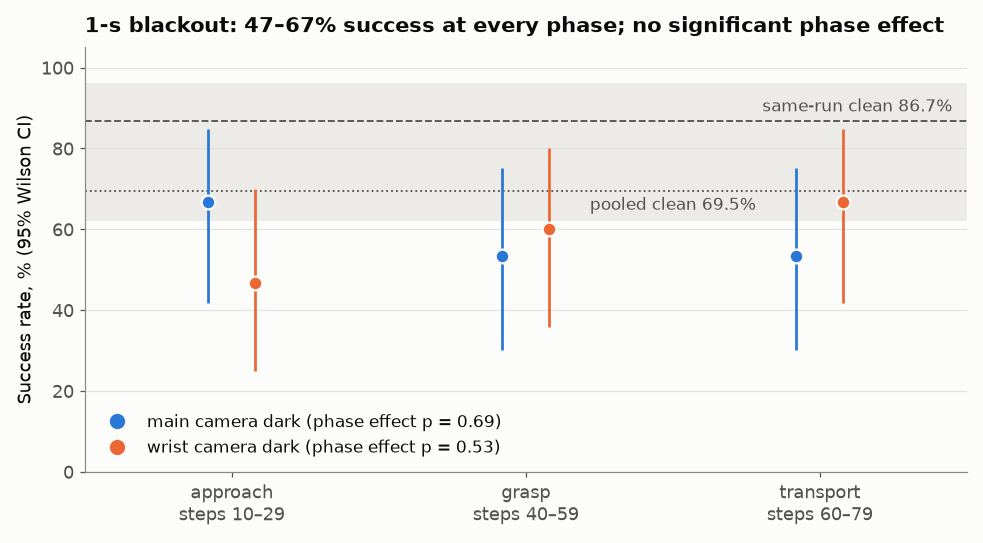

,condition,successes,n,rate,delta_pp_same_run,p_holm_same_run,delta_pp_pooled,p_holm_pooled
0,off_approach_0,10,15,66.7%,-20.0,1.00,-2.9,1.00
1,off_grasp_0,8,15,53.3%,-33.3,1.00,-16.2,1.00
2,off_approach_1,7,15,46.7%,-40.0,1.00,-22.9,1.00
3,off_grasp_1,9,15,60.0%,-26.7,1.00,-9.5,1.00
4,off_transport_0,8,15,53.3%,-33.3,1.00,-16.2,1.00
5,off_transport_1,10,15,66.7%,-20.0,1.00,-2.9,1.00


In [14]:
short = corrupted[corrupted["family"].eq("short_blackout")].copy()
short["phase_order"] = short["phase"].map(PHASE_ORDER)
short_clean = clean_by_run.set_index("run").loc["short_off"]

phase_tests = {}
for camera in ["main", "wrist"]:
    part = episodes[episodes["family"].eq("short_blackout") & episodes["camera"].eq(camera)]
    phase_tests[camera] = stats.chi2_contingency(pd.crosstab(part["phase"], part["success"]))[1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.axhspan(100 * short_clean.ci_low, 100 * short_clean.ci_high, color=CLEAN_BAND, alpha=0.45, lw=0)
ax.axhline(100 * short_clean.rate, color=INK_2, lw=1.2, ls="--")
ax.axhline(100 * CLEAN_RATE, color=INK_2, lw=1.2, ls=":")
ax.text(2.45, 100 * short_clean.rate + 1.5, f"same-run clean {pct(short_clean.rate)}", ha="right", va="bottom",
        fontsize=11, color=INK_2)
ax.text(1.5, 100 * CLEAN_RATE - 1.5, f"pooled clean {pct(CLEAN_RATE)}", ha="center", va="top", fontsize=11, color=INK_2)
for camera, offset in [("main", -0.08), ("wrist", 0.08)]:
    part = short[short["camera"].eq(camera)].sort_values("phase_order")
    x = part["phase_order"] + offset
    rate = 100 * part["rate"]
    ax.errorbar(x, rate, yerr=[rate - 100 * part["ci_low"], 100 * part["ci_high"] - rate], fmt="o", ms=9,
                elinewidth=1.8, color=COLORS[camera], markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.set_xticks(range(3), [f"{p}\nsteps {w}" for p, w in PHASES.items()])
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0, 105)
ax.set_ylabel("Success rate, % (95% Wilson CI)")
short_rates_pct = 100 * short["rate"]
ax.set_title(f"1-s blackout: {short_rates_pct.min():.0f}–{short_rates_pct.max():.0f}% success at every phase; "
             f"{'no significant' if min(phase_tests.values()) >= 0.05 else 'a significant'} phase effect")
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color=COLORS[c],
                           label=f"{c} camera dark (phase effect p = {phase_tests[c]:.2f})") for c in ["main", "wrist"]],
          loc="lower left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "temporary_off_by_phase")
plt.show()

short_view = short.merge(pooled[["condition", "delta_pp", "p_holm"]], on="condition", suffixes=("_same_run", "_pooled"))
show(short_view[["condition", "successes", "n", "rate", "delta_pp_same_run", "p_holm_same_run", "delta_pp_pooled", "p_holm_pooled"]],
     {"rate": "{:.1%}", "delta_pp_same_run": "{:+.1f}", "p_holm_same_run": "{:.2f}",
      "delta_pp_pooled": "{:+.1f}", "p_holm_pooled": "{:.2f}"})

### Three 1-s blackouts in one episode (partial run)

`off_mix_0_1_0` blacks out main → wrist → main at steps 10–29, 40–59 and 80–99. The mirrored schedule `off_mix_1_0_1`
stopped after 3 of 15 episodes, so it is listed only for completeness.

In [15]:
mix = summarize(episodes[episodes["run"].eq("short_off_x3")], ["condition"])
mix["note"] = np.where(mix["n"] < 15, "incomplete run", "")
show(mix[["condition", "successes", "n", "rate", "ci_low", "ci_high", "note"]],
     {"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"})

,condition,successes,n,rate,ci_low,ci_high,note
0,clean,8,15,53.3%,30.1%,75.2%,
1,off_mix_0_1_0,5,15,33.3%,15.2%,58.3%,
2,off_mix_1_0_1,1,3,33.3%,6.1%,79.2%,incomplete run


## 6. Success per task

Success rate for each task and condition (pooled runs). Cells hold only 3–6 episodes (21 for clean), so single cells
are very noisy; the figure is meant to show the overall pattern, e.g. that task 0 is hard even without corruption.

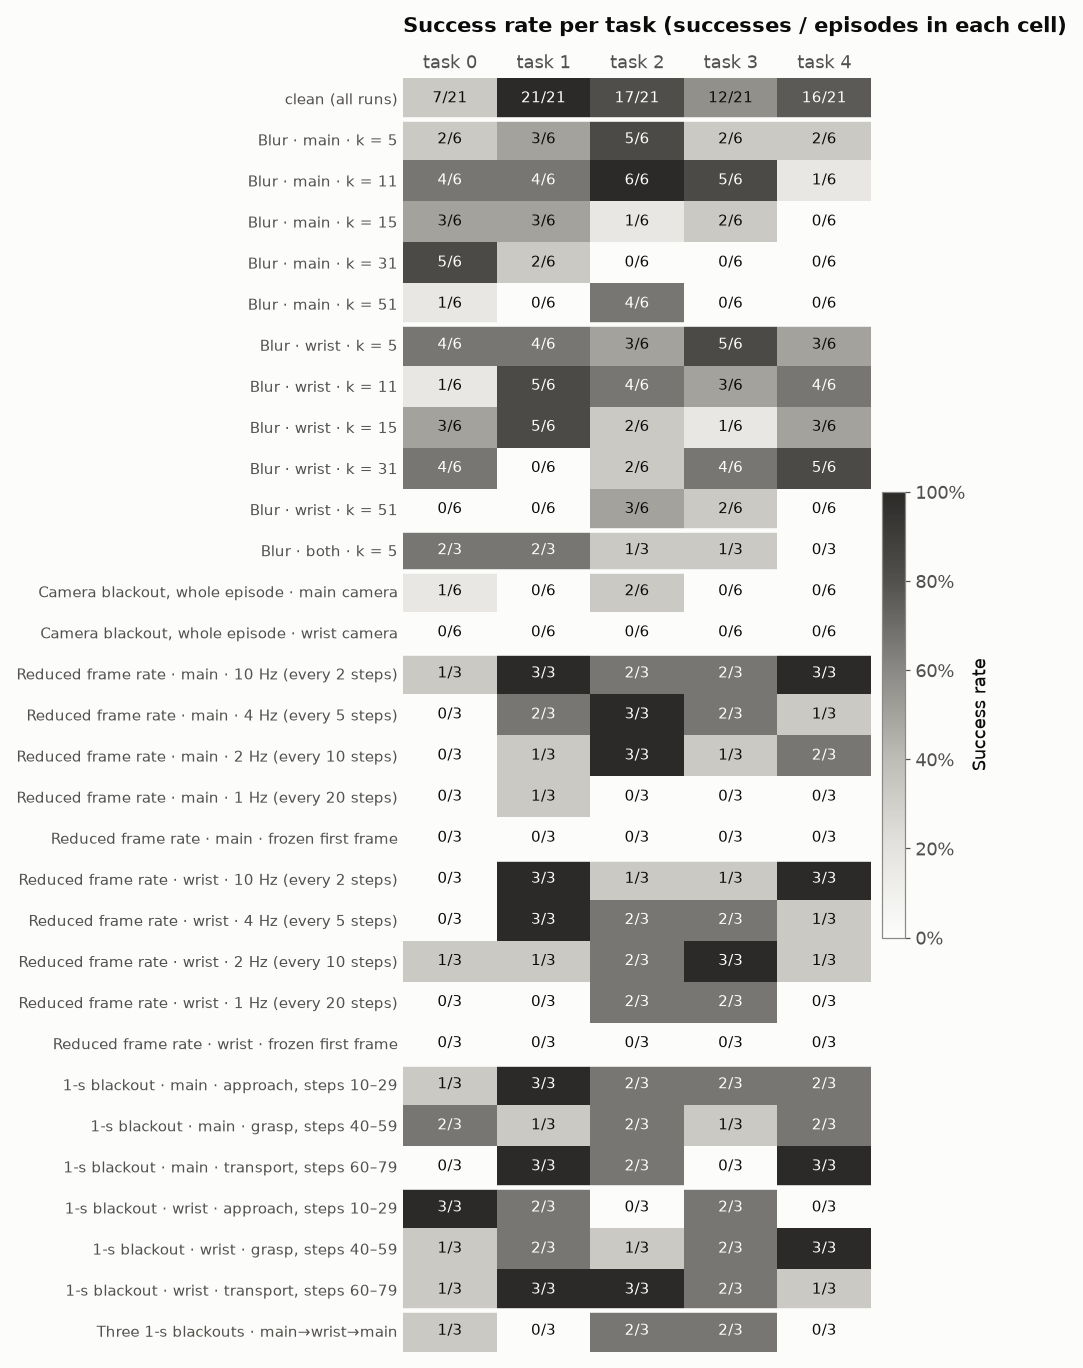

In [16]:
task_table = summarize(episodes[episodes["complete"]], ["condition", "task_id"])
heat = task_table.pivot(index="condition", columns="task_id", values="rate")
counts = task_table.assign(text=lambda d: d["successes"].astype(str) + "/" + d["n"].astype(str)).pivot(
    index="condition", columns="task_id", values="text")
row_order = ["clean"] + ordered["condition"].tolist()
row_labels = ["clean (all runs)"] + [f"{g.split(' · ')[0]} · {r.camera} · {r.label}"
                                     if r.family not in {"blackout", "three_blackouts"} else f"{g} · {r.label}"
                                     for g, r in zip(ordered["group"], ordered.itertuples())]
heat = heat.loc[row_order]
counts = counts.loc[row_order]
group_edges = np.cumsum([1] + ordered.groupby("group", sort=False).size().tolist())[:-1] - 0.5

fig, ax = plt.subplots(figsize=(9, 12.5))
image = ax.imshow(heat.to_numpy(float), cmap=GREYS, vmin=0, vmax=1, aspect="auto")
for (i, j), value in np.ndenumerate(heat.to_numpy(float)):
    # light text on dark cells, dark text on light cells
    ax.text(j, i, counts.iat[i, j], ha="center", va="center", fontsize=9.5, color="white" if value > 0.6 else INK)
for edge in group_edges:
    ax.axhline(edge, color=SURFACE, lw=3)
ax.set_xticks(range(heat.shape[1]), [f"task {t}" for t in heat.columns])
ax.set_yticks(range(len(row_labels)), row_labels, fontsize=10)
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.xaxis.tick_top()
ax.set_title("Success rate per task (successes / episodes in each cell)", pad=30)
fig.colorbar(image, ax=ax, shrink=0.35, pad=0.02, label="Success rate", format=mpl.ticker.PercentFormatter(1.0))
fig.tight_layout()
save(fig, "per_task_heatmap")
plt.show()

## 7. Do corruptions also slow down successful episodes?

Cumulative share of episodes that have succeeded by step *t*. A curve that rises later means slower solutions; a lower
plateau means more failures. Two caveats: the comparison is censored at 140 steps (a slower robot counts as a failure),
and the clean curve is still rising at the limit, so all success rates are lower than with the standard, longer
LIBERO horizon.

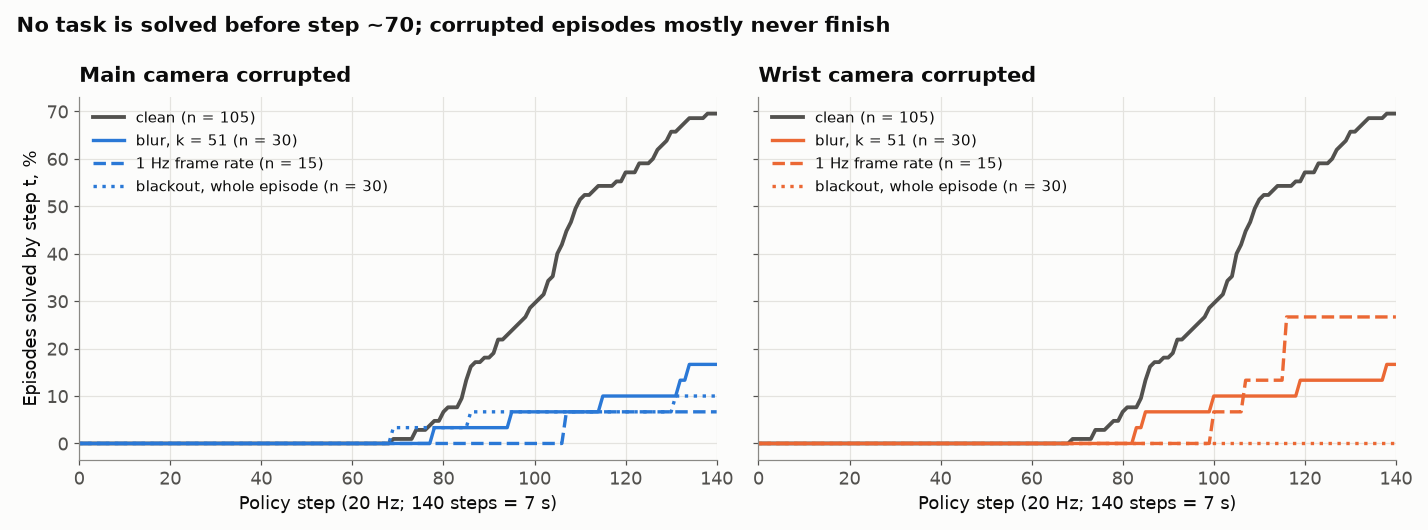

Clean successes in the last 10 steps (131–140): 4 of 73
Episode length of successful episodes (steps), Mann–Whitney vs clean with Holm correction:


,condition,median,mean,successes,p_mannwhitney_vs_clean,p_holm
0,clean,104,102.9,73,,
1,blur_5_0,102,100.8,14,0.751,1.00
2,blur_11_0,95,94.7,20,0.071,1.00
3,blur_15_0,81,87.6,9,0.012,0.31
4,blur_31_0,76,90.4,7,0.068,1.00
5,blur_51_0,115,110.8,5,0.369,1.00
6,blur_5_1,102,102.4,19,0.858,1.00
7,blur_11_1,105,107.1,17,0.424,1.00
8,blur_15_1,116,107.8,14,0.265,1.00
9,blur_31_1,89,98.4,15,0.262,1.00


In [17]:
def success_curve(df):
    t = np.arange(MAX_STEPS + 1)
    done = df.loc[df["success"], "steps"].to_numpy()
    return t, np.array([(done <= step).sum() for step in t]) / len(df)


CURVE_SETS = [
    ("main camera", [("blur_51_0", "blur, k = 51"), ("freeze_20_0", "1 Hz frame rate"), ("turnoff_0", "blackout, whole episode")]),
    ("wrist camera", [("blur_51_1", "blur, k = 51"), ("freeze_20_1", "1 Hz frame rate"), ("turnoff_1", "blackout, whole episode")]),
]
CURVE_STYLES = ["-", "--", ":"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (camera, conditions) in zip(axes, CURVE_SETS):
    t, y = success_curve(clean)
    ax.plot(t, 100 * y, color=COLORS["none"], lw=2.5, label=f"clean (n = {len(clean)})")
    camera_key = camera.split()[0]
    for (condition, name), style in zip(conditions, CURVE_STYLES):
        part = episodes[episodes["condition"].eq(condition) & episodes["complete"]]
        t, y = success_curve(part)
        ax.plot(t, 100 * y, color=COLORS[camera_key], ls=style, lw=2.2, label=f"{name} (n = {len(part)})")
    ax.set_title(f"{camera.capitalize()} corrupted")
    ax.set_xlabel("Policy step (20 Hz; 140 steps = 7 s)")
    ax.set_xlim(0, MAX_STEPS)
    ax.legend(loc="upper left", fontsize=10)
axes[0].set_ylabel("Episodes solved by step t, %")
fig.suptitle("No task is solved before step ~70; corrupted episodes mostly never finish",
             x=0.01, ha="left", fontweight="bold", fontsize=13.5)
fig.tight_layout()
save(fig, "time_to_success")
plt.show()

clean_steps = clean.loc[clean["success"], "steps"]
late_clean = (clean_steps > MAX_STEPS - 10).sum()
print(f"Clean successes in the last 10 steps (131–140): {late_clean} of {len(clean_steps)}")

steps_success = (
    episodes[episodes["success"] & episodes["complete"]]
    .groupby("condition")["steps"].agg(["median", "mean", "size"])
    .rename(columns={"size": "successes"})
)
steps_success["p_mannwhitney_vs_clean"] = [
    stats.mannwhitneyu(episodes.loc[episodes["condition"].eq(c) & episodes["success"], "steps"], clean_steps).pvalue
    if c != "clean" and n >= 3 else np.nan
    for c, n in zip(steps_success.index, steps_success["successes"])
]
tested = steps_success["p_mannwhitney_vs_clean"].notna()
steps_success.loc[tested, "p_holm"] = multipletests(steps_success.loc[tested, "p_mannwhitney_vs_clean"], method="holm")[1]
print("Episode length of successful episodes (steps), Mann–Whitney vs clean with Holm correction:")
show(steps_success.loc[[c for c in row_order if c in steps_success.index]].reset_index(),
     {"median": "{:.0f}", "mean": "{:.1f}", "p_mannwhitney_vs_clean": "{:.3f}", "p_holm": "{:.2f}"})

## 8. Where does the policy look? Cross-attention to each camera

`src/attention_probe.py` records, in the action expert's cross-attention layers 7 and 15 (15 is the last one recorded),
the **attention mass** on each camera: the share of attention placed on that camera's image tokens, summed over its
tokens and averaged over action queries. Here it is also averaged over the 15 heads and the 10 denoising steps
(iterations of the flow-matching action decoder).

**Paired design.** In the attention run every (task, seed) starts from the same initial state in every condition,
and attention is recorded at the first policy step. The effect of a corruption is therefore measured per episode
start as the **relative change** of attention mass vs clean, `100 · (corrupted / clean − 1)` %, then averaged over
the 15 starts (mean ± 95% t-interval).

In [18]:
def camera_attention(df, keys):
    """Attention mass per camera, averaged over heads and denoising steps, one row per `keys`."""
    return (
        df.groupby(keys + ["camera"], as_index=False)["attention_mass"].mean()
        .pivot_table(index=keys, columns="camera", values="attention_mass")
        .rename(columns={"image": "to_main", "image2": "to_wrist"})
        .reset_index()
    )


def relative_to_clean(df, keys):
    """Relative change (%) of attention vs the clean condition with the same `keys`."""
    clean_part = df[df["condition"].eq("clean")].drop(columns="condition")
    out = df.merge(clean_part, on=keys, suffixes=("", "_clean"), validate="many_to_one")
    for target in ["to_main", "to_wrist"]:
        out[f"rel_{target}"] = 100 * (out[target] / out[f"{target}_clean"] - 1)
    return out


attention = pd.read_csv(RESULTS / "attention/libero_spatial_5tasks_3seeds.csv")
per_episode = camera_attention(attention, ["condition", "task_id", "seed", "layer"])
paired = relative_to_clean(per_episode, ["task_id", "seed", "layer"])
assert len(paired) == len(per_episode), "every corrupted episode start must have a clean partner"
paired = paired.join(pd.DataFrame([describe(c) for c in paired["condition"]], index=paired.index))

print("Mean attention mass on camera tokens in clean episodes (the rest goes to language and state tokens):")
show(per_episode[per_episode["condition"].eq("clean")].groupby("layer")[["to_main", "to_wrist"]].mean().reset_index(),
     {"to_main": "{:.3f}", "to_wrist": "{:.3f}"})

Mean attention mass on camera tokens in clean episodes (the rest goes to language and state tokens):


camera,layer,to_main,to_wrist
0,7,0.046,0.120
1,15,0.150,0.200


**Measurement noise.** The controlled probe below re-evaluates clean episode starts (tasks 0–1, seeds 42–43). Comparing
its step-0 clean attention with the attention run gives a clean-vs-clean difference: changes of this size are not
meaningful, so this range is drawn as a hatched band in the next figure.

In [19]:
controlled = pd.read_csv(RESULTS / "controlled_attention/attention.csv")
ctrl = camera_attention(controlled, ["condition", "task_id", "seed", "env_step", "layer"])

clean_a = per_episode[per_episode["condition"].eq("clean")]
clean_b = ctrl[ctrl["condition"].eq("clean") & ctrl["env_step"].eq(0)]
noise = clean_a.merge(clean_b, on=["task_id", "seed", "layer"], suffixes=("_a", "_b"))
for target in ["to_main", "to_wrist"]:
    noise[f"rel_{target}"] = 100 * (noise[f"{target}_b"] / noise[f"{target}_a"] - 1)
ATTENTION_LAYER = int(paired["layer"].max())
NOISE_FLOOR = noise.loc[noise["layer"].eq(ATTENTION_LAYER), ["rel_to_main", "rel_to_wrist"]].abs().to_numpy().max()
show(noise[["task_id", "seed", "layer", "rel_to_main", "rel_to_wrist"]], {"rel_to_main": "{:+.1f}%", "rel_to_wrist": "{:+.1f}%"})
print(f"Largest clean-vs-clean difference at layer {ATTENTION_LAYER}: ±{NOISE_FLOOR:.1f}%")

camera,task_id,seed,layer,rel_to_main,rel_to_wrist
0,0,42,7,-0.1%,+0.4%
1,0,42,15,-0.2%,-0.1%
2,0,43,7,+3.5%,+2.2%
3,0,43,15,-3.6%,+0.1%
4,1,42,7,-0.2%,+0.4%
5,1,42,15,-0.5%,-0.2%
6,1,43,7,+1.4%,+5.3%
7,1,43,15,-2.2%,+5.5%


Largest clean-vs-clean difference at layer 15: ±5.5%


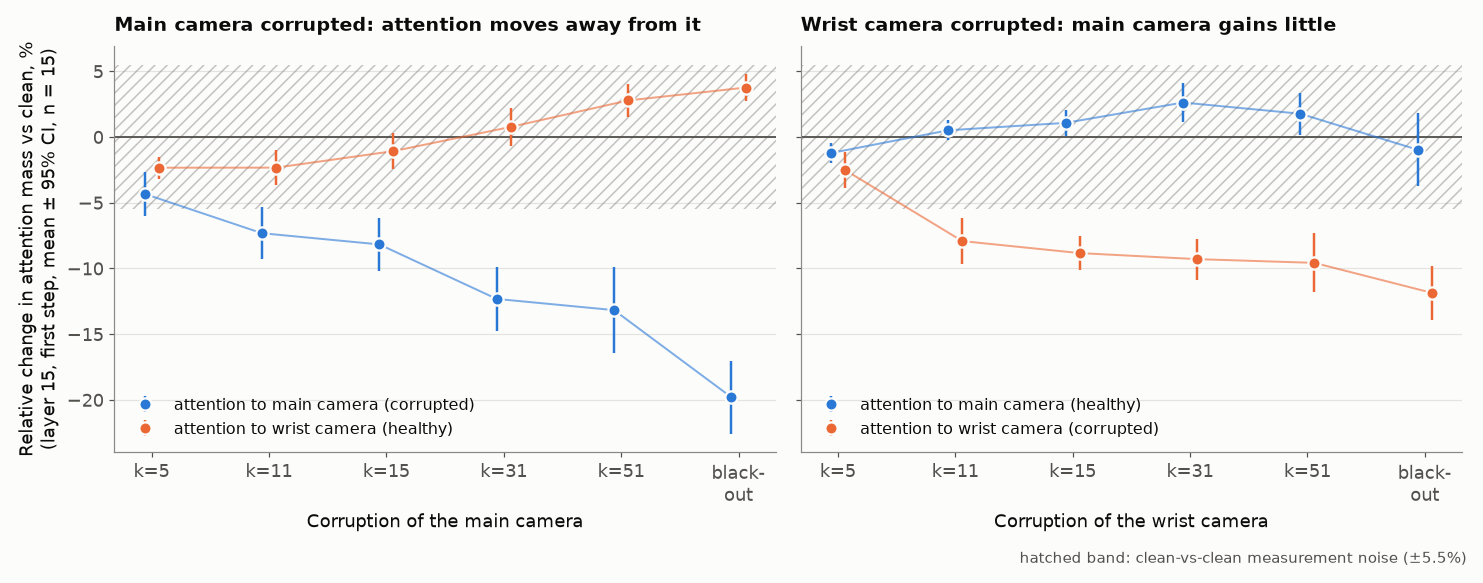

In [20]:
def attention_curve(layer, corrupted_camera, target):
    sub = paired[paired["layer"].eq(layer) & paired["camera"].eq(corrupted_camera)]
    values = [sub.loc[sub["family"].eq("blur") & sub["level"].eq(k), f"rel_{target}"] for k in BLUR_LEVELS]
    values.append(sub.loc[sub["family"].eq("blackout"), f"rel_{target}"])
    rows = []
    for v in values:
        v = np.asarray(v, float)
        rows.append((v.mean(), stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))))
    return np.array(rows)


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)
x = np.arange(len(BLUR_LEVELS) + 1)
titles = {"main": "Main camera corrupted: attention moves away from it",
          "wrist": "Wrist camera corrupted: main camera gains little"}
for ax, corrupted_camera in zip(axes, ["main", "wrist"]):
    ax.axhspan(-NOISE_FLOOR, NOISE_FLOOR, facecolor="none", edgecolor=INK_3, hatch="///", lw=0, alpha=0.5)
    ax.axhline(0, color=INK_2, lw=1.2)
    for target, offset in [("to_main", -0.06), ("to_wrist", 0.06)]:
        target_camera = target.split("_")[1]
        curve = attention_curve(ATTENTION_LAYER, corrupted_camera, target)
        role = "corrupted" if target_camera == corrupted_camera else "healthy"
        ax.plot(x + offset, curve[:, 0], color=COLORS[target_camera], lw=1.3, alpha=0.6)
        ax.errorbar(x + offset, curve[:, 0], yerr=curve[:, 1], fmt="o", ms=8, elinewidth=1.6,
                    color=COLORS[target_camera], markeredgecolor=SURFACE, markeredgewidth=1.5,
                    label=f"attention to {target_camera} camera ({role})")
    ax.set_xticks(x, [f"k={k}" for k in BLUR_LEVELS] + ["black-\nout"])
    ax.set_xlabel(f"Corruption of the {corrupted_camera} camera")
    ax.set_title(titles[corrupted_camera], fontsize=12.5)
    ax.legend(loc="lower left", fontsize=10.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel(f"Relative change in attention mass vs clean, %\n(layer {ATTENTION_LAYER}, first step, mean ± 95% CI, n = 15)")
fig.text(0.99, 0.01, f"hatched band: clean-vs-clean measurement noise (±{NOISE_FLOOR:.1f}%)", ha="right",
         fontsize=10, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "attention_shift")
plt.show()

### The effect depends on the layer

Mean relative change (%) for the strongest blur and for blackout in both recorded layers. Layer 7 behaves differently
from layer 15: there a black main image *attracts* attention instead of losing it, and blurring the wrist camera
raises attention to the healthy main camera.

In [21]:
layer_table = (
    paired[paired["condition"].isin(["blur_51_0", "blur_51_1", "turnoff_0", "turnoff_1"])]
    .groupby(["condition", "layer"])[["rel_to_main", "rel_to_wrist"]]
    .mean()
    .reset_index()
)
show(layer_table, {"rel_to_main": "{:+.1f}%", "rel_to_wrist": "{:+.1f}%"})

,condition,layer,rel_to_main,rel_to_wrist
0,blur_51_0,7,-3.4%,+7.4%
1,blur_51_0,15,-13.2%,+2.8%
2,blur_51_1,7,+9.5%,-13.1%
3,blur_51_1,15,+1.8%,-9.6%
4,turnoff_0,7,+10.7%,+8.0%
5,turnoff_0,15,-19.8%,+3.7%
6,turnoff_1,7,+3.5%,-13.0%
7,turnoff_1,15,-1.0%,-11.9%


### Controlled attention along clean trajectories

`src/controlled_attention.py` follows **clean** rollouts (tasks 0–1, seeds 42–43) and, at steps 0/15/30/45/60, feeds the
very same observation three times: clean, main camera blurred (k = 51) and wrist camera blurred (k = 51). This isolates
the attention response from any change of trajectory. Lines are the mean of the 4 states, shading their min–max range.

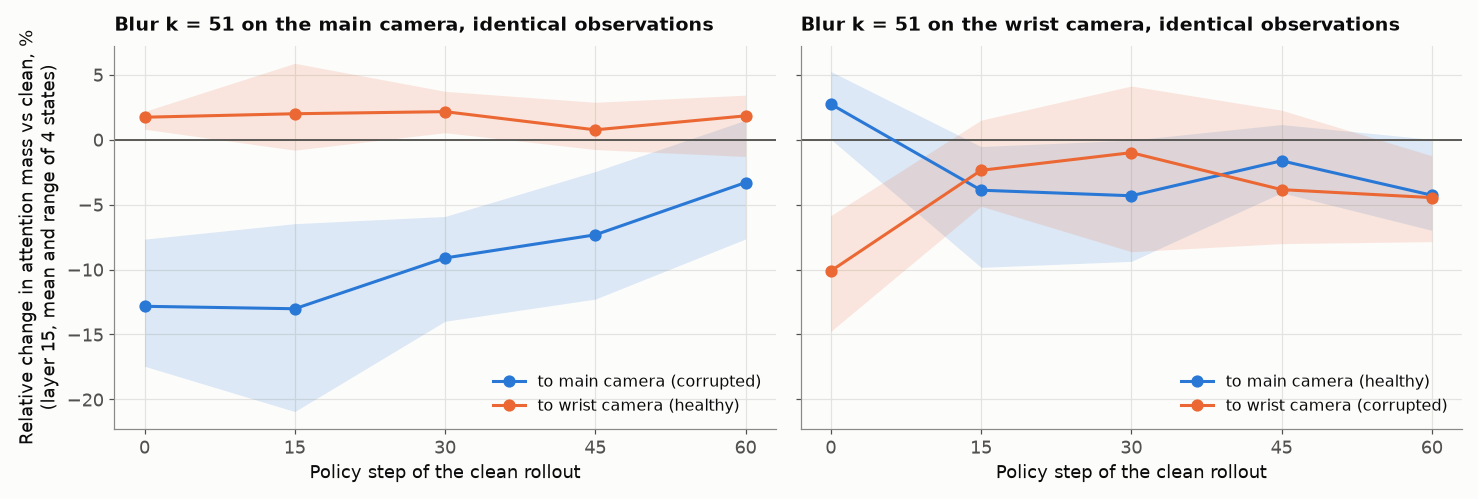

In [22]:
ctrl_rel = relative_to_clean(ctrl, ["task_id", "seed", "env_step", "layer"])
ctrl_rel = ctrl_rel[ctrl_rel["condition"].ne("clean") & ctrl_rel["layer"].eq(ATTENTION_LAYER)]
ctrl_stats = ctrl_rel.groupby(["condition", "env_step"])[["rel_to_main", "rel_to_wrist"]].agg(["mean", "min", "max"])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
for ax, (condition, corrupted_camera) in zip(axes, [("blur_51_0", "main"), ("blur_51_1", "wrist")]):
    ax.axhline(0, color=INK_2, lw=1.2)
    part = ctrl_stats.loc[condition]
    for target in ["to_main", "to_wrist"]:
        target_camera = target.split("_")[1]
        role = "corrupted" if target_camera == corrupted_camera else "healthy"
        column = f"rel_{target}"
        ax.fill_between(part.index, part[(column, "min")], part[(column, "max")], color=COLORS[target_camera], alpha=0.15, lw=0)
        ax.plot(part.index, part[(column, "mean")], marker="o", ms=7, color=COLORS[target_camera],
                label=f"to {target_camera} camera ({role})")
    ax.set_title(f"Blur k = 51 on the {corrupted_camera} camera, identical observations", fontsize=12.5)
    ax.set_xlabel("Policy step of the clean rollout")
    ax.set_xticks(sorted(ctrl_rel["env_step"].unique()))
    ax.legend(loc="lower right", fontsize=10.5)
axes[0].set_ylabel(f"Relative change in attention mass vs clean, %\n(layer {ATTENTION_LAYER}, mean and range of 4 states)")
fig.tight_layout()
save(fig, "attention_controlled")
plt.show()

### Does a bigger attention shift predict success?

For single-camera blur and blackout episodes of the attention run we compare the attention change at the first step
between successful and failed episodes (Mann–Whitney U test, uncorrected). Severity and task drive both attention and
success, so the "within" columns first subtract the mean of each condition × task group.

In [23]:
single = paired[paired["layer"].eq(ATTENTION_LAYER) & paired["family"].isin(["blur", "blackout"])
                & paired["camera"].isin(["main", "wrist"])].copy()
single["rel_healthy"] = np.where(single["camera"].eq("main"), single["rel_to_wrist"], single["rel_to_main"])
single["rel_corrupted"] = np.where(single["camera"].eq("main"), single["rel_to_main"], single["rel_to_wrist"])
outcomes = load_rollouts(RESULTS / "attention/rollouts_5tasks_3seeds.csv")[["condition", "task_id", "seed", "success"]]
single = single.merge(outcomes, on=["condition", "task_id", "seed"], validate="one_to_one")
for column in ["rel_healthy", "rel_corrupted"]:
    single[f"{column}_within"] = single[column] - single.groupby(["condition", "task_id"])[column].transform("mean")

rows = []
for camera, part in single.groupby("camera"):
    win, lose = part["success"], ~part["success"]
    for column in ["rel_healthy", "rel_corrupted"]:
        within = f"{column}_within"
        rows.append({
            "corrupted camera": camera, "attention to": column.replace("rel_", "") + " camera",
            "mean, success": part.loc[win, column].mean(), "mean, failure": part.loc[lose, column].mean(),
            "raw p": stats.mannwhitneyu(part.loc[win, column], part.loc[lose, column]).pvalue,
            "within Δ (success − failure)": part.loc[win, within].mean() - part.loc[lose, within].mean(),
            "within p": stats.mannwhitneyu(part.loc[win, within], part.loc[lose, within]).pvalue,
            "n success": int(win.sum()), "n failure": int(lose.sum()),
        })
attention_outcome = pd.DataFrame(rows)
show(attention_outcome, {"mean, success": "{:+.1f}%", "mean, failure": "{:+.1f}%", "raw p": "{:.3f}",
                          "within Δ (success − failure)": "{:+.1f} pp", "within p": "{:.3f}"})

,corrupted camera,attention to,"mean, success","mean, failure",raw p,within Δ (success − failure),within p,n success,n failure
0,main,healthy camera,-1.0%,+0.8%,0.007,-0.2 pp,0.376,28,62
1,main,corrupted camera,-8.6%,-11.9%,0.044,+0.2 pp,0.673,28,62
2,wrist,healthy camera,+0.9%,+0.5%,0.626,+0.5 pp,0.073,34,56
3,wrist,corrupted camera,-7.1%,-9.1%,0.033,+0.0 pp,0.983,34,56


## 9. Summary

The summary is generated from the results above, so its numbers stay correct when experiments are added or re-run.

In [24]:
P = pooled.set_index("condition")


def rate(condition):
    return 100 * P.loc[condition, "rate"]


def r0(condition):
    """Success rate as a whole percent, e.g. '17%'."""
    return f"{rate(condition):.0f}%"


def rk(condition):
    """Rate with counts, e.g. '17% (5/30)'."""
    row = P.loc[condition]
    return f"{100 * row.rate:.0f}% ({row.successes}/{row.n})"


def span(values, unit="%"):
    values = [round(v) for v in values]
    return f"{min(values)}–{max(values)}{unit}"


def significance(condition):
    return "significant" if P.loc[condition, "p_holm"] < 0.05 else "not significant after correction"


cmh = camera_compare.set_index("family")["p"]
run_rates = 100 * clean_by_run["rate"]
significant_drops = -pooled.loc[pooled["p_holm"] < 0.05, "delta_pp"]
short_rates = [rate(c) for c in short["condition"]]
attention_main = attention_curve(ATTENTION_LAYER, "main", "to_main")[:, 0]     # k = 5 ... 51, blackout
attention_wrist = attention_curve(ATTENTION_LAYER, "wrist", "to_wrist")[:, 0]
healthy_gain = max(attention_curve(ATTENTION_LAYER, "main", "to_wrist")[:, 0].max(),
                   attention_curve(ATTENTION_LAYER, "wrist", "to_main")[:, 0].max())
layer7_black_main = layer_table.set_index(["condition", "layer"]).loc[("turnoff_0", 7), "rel_to_main"]
within_p_min = attention_outcome["within p"].min()
frozen = sorted({r0("freeze_140_0"), r0("freeze_140_1")})

S = {  # every number quoted in the summary and in the README
    "clean_rate": pct(CLEAN_RATE),
    "clean_counts": f"{pooled_clean.successes}/{pooled_clean.n}",
    "clean_ci": f"{100 * CLEAN_LOW:.0f}–{100 * CLEAN_HIGH:.0f}%",
    "run_low": f"{run_rates.min():.0f}%", "run_high": f"{run_rates.max():.0f}%",
    "n_runs": len(clean_by_run),
    "chi2_p": f"{chi2_p:.2f}",
    "mixed_pairs": f"{mixed_pairs} of the {len(outcome_per_pair)}",
    "min_significant_drop": f"{significant_drops.min():.0f} pp",
    "blackout_span": span([rate("turnoff_0"), rate("turnoff_1")]),
    "blur_main_mid": span([rate("blur_15_0"), rate("blur_31_0")]),
    "blur_wrist_mid": span([rate("blur_15_1"), rate("blur_31_1")]),
    "cmh_blur": f"{cmh['blur']:.2f}", "cmh_rate": f"{cmh['frame_rate']:.2f}",
    "rate_ok_span": span([rate(f"freeze_{p}_{c}") for p in [2, 5, 10] for c in [0, 1]]),
    "short_span": span(short_rates),
    "short_clean": f"{100 * short_clean.rate:.0f}%",
    "short_delta_same_run": span(-short["delta_pp"], " pp"),
    "short_delta_pooled": span([-P.loc[c, "delta_pp"] for c in short["condition"]], " pp"),
    "phase_p_main": f"{phase_tests['main']:.2f}", "phase_p_wrist": f"{phase_tests['wrist']:.2f}",
    "task_low": f"{100 * clean_by_task['rate'].min():.0f}%", "task_high": f"{100 * clean_by_task['rate'].max():.0f}%",
    "att_main": [f"{-v:.0f}%" for v in attention_main[[0, 4, 5]]],
    "att_wrist": [f"{-v:.0f}%" for v in attention_wrist[[0, 4, 5]]],
    "healthy_gain": f"+{healthy_gain:.0f}%",
    "noise": f"±{NOISE_FLOOR:.1f}%",
}

blur_trend = "a trend" if cmh["blur"] >= 0.05 else "significant"
phase_effect = ("No phase effect is significant" if min(phase_tests.values()) >= 0.05
                else "The phase effect is significant for at least one camera")
summary = f"""
Pooled clean success: **{S['clean_rate']}** ({S['clean_counts']}, 95% CI {S['clean_ci']}), LIBERO-Spatial tasks 0–4 × seeds 42–44.

1. **Evaluation noise is large.** Clean success varies from {S['run_low']} to {S['run_high']} between {S['n_runs']} identical runs
   (no evidence of run differences, χ² p = {S['chi2_p']}), and {S['mixed_pairs']} (task, seed) pairs flip between success and
   failure across runs. After Holm correction the smallest significant drop against pooled clean is
   {S['min_significant_drop']}; smaller differences are trends.
2. **SmolVLA cannot work without either camera.** A whole-episode blackout leaves {rk('turnoff_0')} success without the main
   camera and {rk('turnoff_1')} without the wrist camera; a frozen first frame gives {' / '.join(frozen)}. A black or frozen image is
   also an input the model never saw in training, so this measures failure under out-of-distribution input, not only a missing view.
3. **Blur degrades both cameras; the main camera tends to fail at milder blur.** At k = 15–31 success is {S['blur_main_mid']}
   (main) vs {S['blur_wrist_mid']} (wrist; CMH p = {S['cmh_blur']}, {blur_trend}). At k = 51: main {r0('blur_51_0')}, wrist
   {r0('blur_51_1')}. The dip at main k = 5 ({r0('blur_5_0')}) next to k = 11 ({r0('blur_11_0')}) is within noise.
4. **A reduced frame rate shows no significant loss down to 2 Hz but collapses at 1 Hz.** At 10/4/2 Hz success is
   {S['rate_ok_span']}; at 1 Hz it is {r0('freeze_20_0')} (main, {significance('freeze_20_0')}) and {r0('freeze_20_1')}
   (wrist, {significance('freeze_20_1')}). We find no detectable difference between the cameras (CMH p = {S['cmh_rate']}).
5. **A 1-s blackout costs much less than a permanent one.** Success is {S['short_span']} at every phase, i.e.
   {S['short_delta_same_run']} below same-run clean ({S['short_clean']}) and {S['short_delta_pooled']} below pooled clean.
   {phase_effect} (p = {S['phase_p_main']} main, {S['phase_p_wrist']} wrist). Three alternating 1-s blackouts give
   {rk('off_mix_0_1_0')}.
6. **Successful episodes are not consistently slower,** but this comparison is censored at {MAX_STEPS} steps and covers only
   the episodes that still succeed. {late_clean} of {len(clean_steps)} clean successes arrive in the last 10 steps, so the
   step limit keeps clean success below the ≈90% reported for SmolVLA on LIBERO-Spatial with the standard horizon.
7. **Task difficulty dominates.** Clean success ranges from {S['task_low']} to {S['task_high']} across tasks; per-task cells
   under corruption hold only 3–6 episodes, so we do not draw per-task conclusions.
8. **Attention leaves a degraded camera but barely moves to the healthy one (layer {ATTENTION_LAYER}).** Attention to the
   corrupted camera falls by {' → '.join(S['att_main'])} (main, k = 5 → k = 51 → blackout) and {' → '.join(S['att_wrist'])}
   (wrist), relative to clean. The healthy camera gains at most {S['healthy_gain']}, inside the {S['noise']} clean-vs-clean
   noise. Layer 7 behaves differently (a black main image changes attention to it by {layer7_black_main:+.0f}%). Within a
   condition the attention shift does not predict success (smallest p = {within_p_min:.2f}; low power).

**Limitations.** One suite, five tasks, three seeds; {MAX_STEPS}-step limit; the pooled blur/blackout episodes are the same
15 starts run twice; attention is measured only at the first step (and at five states in the controlled probe); the
`off_mix_1_0_1` run is incomplete.
"""
display(Markdown(summary))


Pooled clean success: **69.5%** (73/105, 95% CI 60–78%), LIBERO-Spatial tasks 0–4 × seeds 42–44.

1. **Evaluation noise is large.** Clean success varies from 53% to 87% between 7 identical runs
   (no evidence of run differences, χ² p = 0.34), and 10 of the 15 (task, seed) pairs flip between success and
   failure across runs. After Holm correction the smallest significant drop against pooled clean is
   40 pp; smaller differences are trends.
2. **SmolVLA cannot work without either camera.** A whole-episode blackout leaves 10% (3/30) success without the main
   camera and 0% (0/30) without the wrist camera; a frozen first frame gives 0%. A black or frozen image is
   also an input the model never saw in training, so this measures failure under out-of-distribution input, not only a missing view.
3. **Blur degrades both cameras; the main camera tends to fail at milder blur.** At k = 15–31 success is 23–30%
   (main) vs 47–50% (wrist; CMH p = 0.09, a trend). At k = 51: main 17%, wrist
   17%. The dip at main k = 5 (47%) next to k = 11 (67%) is within noise.
4. **A reduced frame rate shows no significant loss down to 2 Hz but collapses at 1 Hz.** At 10/4/2 Hz success is
   47–73%; at 1 Hz it is 7% (main, significant) and 27%
   (wrist, not significant after correction). We find no detectable difference between the cameras (CMH p = 1.00).
5. **A 1-s blackout costs much less than a permanent one.** Success is 47–67% at every phase, i.e.
   20–40 pp below same-run clean (87%) and 3–23 pp below pooled clean.
   No phase effect is significant (p = 0.69 main, 0.53 wrist). Three alternating 1-s blackouts give
   33% (5/15).
6. **Successful episodes are not consistently slower,** but this comparison is censored at 140 steps and covers only
   the episodes that still succeed. 4 of 73 clean successes arrive in the last 10 steps, so the
   step limit keeps clean success below the ≈90% reported for SmolVLA on LIBERO-Spatial with the standard horizon.
7. **Task difficulty dominates.** Clean success ranges from 33% to 100% across tasks; per-task cells
   under corruption hold only 3–6 episodes, so we do not draw per-task conclusions.
8. **Attention leaves a degraded camera but barely moves to the healthy one (layer 15).** Attention to the
   corrupted camera falls by 4% → 13% → 20% (main, k = 5 → k = 51 → blackout) and 3% → 10% → 12%
   (wrist), relative to clean. The healthy camera gains at most +4%, inside the ±5.5% clean-vs-clean
   noise. Layer 7 behaves differently (a black main image changes attention to it by +11%). Within a
   condition the attention shift does not predict success (smallest p = 0.07; low power).

**Limitations.** One suite, five tasks, three seeds; 140-step limit; the pooled blur/blackout episodes are the same
15 starts run twice; attention is measured only at the first step (and at five states in the controlled probe); the
`off_mix_1_0_1` run is incomplete.


## 10. Check that the README matches the data

`README.md` is static text. This cell rebuilds every number the README quotes from the results above and lists any
statement that is no longer in the README. If the data change, it fails with the exact text to update.

In [25]:
readme = " ".join((ROOT / "README.md").read_text(encoding="utf-8").split())


def cell(condition):
    """README table cell: rate with counts, bold if significantly below pooled clean."""
    text = rk(condition)
    return f"**{text}**" if P.loc[condition, "p_holm"] < 0.05 else text


README_TABLE = {
    **{f"Blur, k = {k}": (f"blur_{k}_0", f"blur_{k}_1") for k in BLUR_LEVELS},
    "Camera blackout, whole episode": ("turnoff_0", "turnoff_1"),
    **{f"Frame rate {POLICY_HZ / p:g} Hz": (f"freeze_{p}_0", f"freeze_{p}_1") for p in [2, 5, 10, 20]},
    "Frozen first frame": ("freeze_140_0", "freeze_140_1"),
    **{f"1-s blackout, {phase}": (f"off_{phase}_0", f"off_{phase}_1") for phase in PHASES},
}
expected = [(f"table row: {name}", f"| {name} | {cell(main)} | {cell(wrist)} |")
            for name, (main, wrist) in README_TABLE.items()]
expected += [
    ("abstract: clean success", f"clean success {S['clean_rate']}"),
    ("abstract: blackout range", f"reduces success to {S['blackout_span']}"),
    ("clean range across runs", f"between {S['run_low']} and {S['run_high']} across the"),
    ("clean χ² test", f"(χ² test, p = {S['chi2_p']})"),
    ("flipping (task, seed) pairs", f"{S['mixed_pairs']} pairs"),
    ("pooled clean baseline", f"pooled clean baseline of {S['clean_rate']}** ({S['clean_counts']}, 95% CI {S['clean_ci']})"),
    ("significance threshold", f"about **{S['min_significant_drop']} or more**"),
    ("whole-episode blackout", f"leaves **{r0('turnoff_0')}** success without the main camera and **{r0('turnoff_1')}** without the wrist camera"),
    ("frozen first frame", f"A **frozen first frame** gives **{frozen[0]}** for both cameras" if len(frozen) == 1 else "frozen differs between cameras"),
    ("blur k = 15–31", f"(k = 15–31: {S['blur_main_mid']} vs {S['blur_wrist_mid']} for the wrist camera)"),
    ("blur k = 51", f"both reach {r0('blur_51_0')} at k = 51" if r0("blur_51_0") == r0("blur_51_1") else "blur k = 51 differs between cameras"),
    ("blur camera test", f"(CMH test over kernel sizes, p = {S['cmh_blur']})"),
    ("frame rate ≥ 2 Hz", f"down to 2 Hz ({S['rate_ok_span']} success)"),
    ("frame rate 1 Hz", f"(main {r0('freeze_20_0')}, {significance('freeze_20_0')}; wrist {r0('freeze_20_1')}, {significance('freeze_20_1')})"),
    ("1-s blackout range", f"success stays at **{S['short_span']}** in every phase"),
    ("1-s blackout vs same-run clean", f"That is {S['short_delta_same_run']} below the clean episodes of the same run ({S['short_clean']}"),
    ("1-s blackout vs pooled clean", f"but only {S['short_delta_pooled']} below the pooled baseline"),
    ("phase tests", f"(p = {S['phase_p_main']} for the main camera, {S['phase_p_wrist']} for the wrist camera)"),
    ("three 1-s blackouts", f"Three alternating 1-s blackouts in one episode give {rk('off_mix_0_1_0')}"),
    ("attention, main camera", f"it drops by {S['att_main'][0]} at k = 5, {S['att_main'][1]} at k = 51 and {S['att_main'][2]} under blackout"),
    ("attention, wrist camera", f"for the wrist camera by {S['att_wrist'][0]}, {S['att_wrist'][1]} and {S['att_wrist'][2]}"),
    ("attention, healthy gain", f"The healthy camera gains at most {S['healthy_gain']}, inside the {S['noise']}"),
    ("extra: blur on both cameras", f"blur k = 5 on both cameras {rk('blur_5_0_1')}"),
    ("extra: three blackouts", f"three 1-s blackouts {rk('off_mix_0_1_0')}"),
    ("table footnote", f"Pooled clean: {S['clean_rate']} ({S['clean_counts']})"),
]

readme_check = pd.DataFrame([{"statement": what, "expected text": text, "in README": text in readme}
                             for what, text in expected])
stale = readme_check[~readme_check["in README"]]
print(f"{len(readme_check) - len(stale)}/{len(readme_check)} README statements match the data")
if len(stale):
    display(stale)
assert stale.empty, f"README.md is out of date: update the {len(stale)} statement(s) listed above"

39/39 README statements match the data


## 11. Does corruption-aware LoRA improve robustness?

The comparison from `effects.ipynb`, restricted to the same **tasks 0–2, seeds 42/43/44**, with a
140-step limit: **9 episodes per condition and model**. The fine-tuned results come from
`robust_lora_3tasks_3seeds.csv`. Original blur and full blackout use
`visual_robustness_5tasks_3seeds_batch.csv`; temporary blackout uses
`temporary_off_single_5tasks_3seeds.csv`. Each source retains its own clean reference.

Points and error bars show success rates and **95% Wilson intervals**. Camera colours follow the earlier figures;
filled circles / solid lines denote the original model, open squares / dashed lines denote robust LoRA.
One success changes the rate by 11.1 pp. These are descriptive comparisons of separate evaluation runs;
the same task/seed does not guarantee a deterministic rollout. No pooled five-task baseline is used here.

In [26]:
ROBUST_MODELS = ["Original SmolVLA", "SmolVLA + robust LoRA"]
ROBUST_STYLE = {ROBUST_MODELS[0]: ("o", "-", -0.06), ROBUST_MODELS[1]: ("s", "--", 0.06)}
robust_lora = load_rollouts(RESULTS / "robust_lora_3tasks_3seeds.csv")
robust_sources = {
    "blur / full blackout": load_rollouts(RESULTS / "visual_robustness_5tasks_3seeds_batch.csv"),
    "temporary blackout": load_rollouts(RESULTS / "temporary_off_single_5tasks_3seeds.csv"),
}
robust_groups = {
    "blur / full blackout": ["clean"] + [f"blur_{k}_{c}" for c in [0, 1] for k in [5, 31]] + ["turnoff_0", "turnoff_1"],
    "temporary blackout": ["clean"] + [f"off_{phase}_{c}" for c in [0, 1] for phase in PHASES],
}
robust_frames = []
expected_pairs = {(task, seed) for task in [0, 1, 2] for seed in [42, 43, 44]}
for group, conditions in robust_groups.items():
    for model, raw in zip(ROBUST_MODELS, [robust_sources[group], robust_lora]):
        part = raw[raw["task_id"].isin([0, 1, 2]) & raw["seed"].isin([42, 43, 44])
                   & raw["condition"].isin(conditions)].copy()
        assert not part.duplicated(["condition", "task_id", "seed"]).any()
        assert part["steps"].le(MAX_STEPS).all()
        for condition in conditions:
            subset = part[part["condition"].eq(condition)]
            assert set(zip(subset.task_id, subset.seed)) == expected_pairs, (model, condition)
        robust_frames.append(part.assign(model=model, comparison=group))

robust_rates = summarize(pd.concat(robust_frames, ignore_index=True), ["comparison", "model", "condition"])
robust_clean = robust_rates[robust_rates.condition.eq("clean")][["comparison", "model", "rate"]].rename(columns={"rate": "clean_rate"})
robust_rates = robust_rates.merge(robust_clean, on=["comparison", "model"], validate="many_to_one")
robust_rates["delta_vs_clean_pp"] = 100 * (robust_rates.rate - robust_rates.clean_rate)
robust_rates.to_csv(TABLES / "robust_lora_success.csv", index=False)
robust_comparison = robust_rates.pivot(index=["comparison", "condition"], columns="model", values="rate").reindex(columns=ROBUST_MODELS)
robust_comparison["LoRA − original, pp"] = 100 * (robust_comparison[ROBUST_MODELS[1]] - robust_comparison[ROBUST_MODELS[0]])
robust_comparison.to_csv(TABLES / "robust_lora_comparison.csv")
show(robust_rates[["comparison", "model", "condition", "successes", "n", "rate", "ci_low", "ci_high", "delta_vs_clean_pp"]],
     {"rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}", "delta_vs_clean_pp": "{:+.1f}"})
show(robust_comparison.reset_index(), {**{m: "{:.1%}" for m in ROBUST_MODELS}, "LoRA − original, pp": "{:+.1f}"})

,comparison,model,condition,successes,n,rate,ci_low,ci_high,delta_vs_clean_pp
0,blur / full blackout,Original SmolVLA,clean,7,9,77.8%,45.3%,93.7%,+0.0
1,blur / full blackout,Original SmolVLA,blur_5_0,4,9,44.4%,18.9%,73.3%,-33.3
2,blur / full blackout,Original SmolVLA,blur_31_0,3,9,33.3%,12.1%,64.6%,-44.4
3,blur / full blackout,Original SmolVLA,blur_5_1,6,9,66.7%,35.4%,87.9%,-11.1
4,blur / full blackout,Original SmolVLA,blur_31_1,3,9,33.3%,12.1%,64.6%,-44.4
5,blur / full blackout,Original SmolVLA,turnoff_0,2,9,22.2%,6.3%,54.7%,-55.6
6,blur / full blackout,Original SmolVLA,turnoff_1,0,9,0.0%,0.0%,29.9%,-77.8
7,blur / full blackout,SmolVLA + robust LoRA,clean,7,9,77.8%,45.3%,93.7%,+0.0
8,blur / full blackout,SmolVLA + robust LoRA,blur_5_0,6,9,66.7%,35.4%,87.9%,-11.1
9,blur / full blackout,SmolVLA + robust LoRA,blur_31_0,4,9,44.4%,18.9%,73.3%,-33.3


model,comparison,condition,Original SmolVLA,SmolVLA + robust LoRA,"LoRA − original, pp"
0,blur / full blackout,blur_31_0,33.3%,44.4%,+11.1
1,blur / full blackout,blur_31_1,33.3%,33.3%,+0.0
2,blur / full blackout,blur_5_0,44.4%,66.7%,+22.2
3,blur / full blackout,blur_5_1,66.7%,55.6%,-11.1
4,blur / full blackout,clean,77.8%,77.8%,+0.0
5,blur / full blackout,turnoff_0,22.2%,22.2%,+0.0
6,blur / full blackout,turnoff_1,0.0%,0.0%,+0.0
7,temporary blackout,clean,88.9%,77.8%,-11.1
8,temporary blackout,off_approach_0,66.7%,100.0%,+33.3
9,temporary blackout,off_approach_1,55.6%,66.7%,+11.1


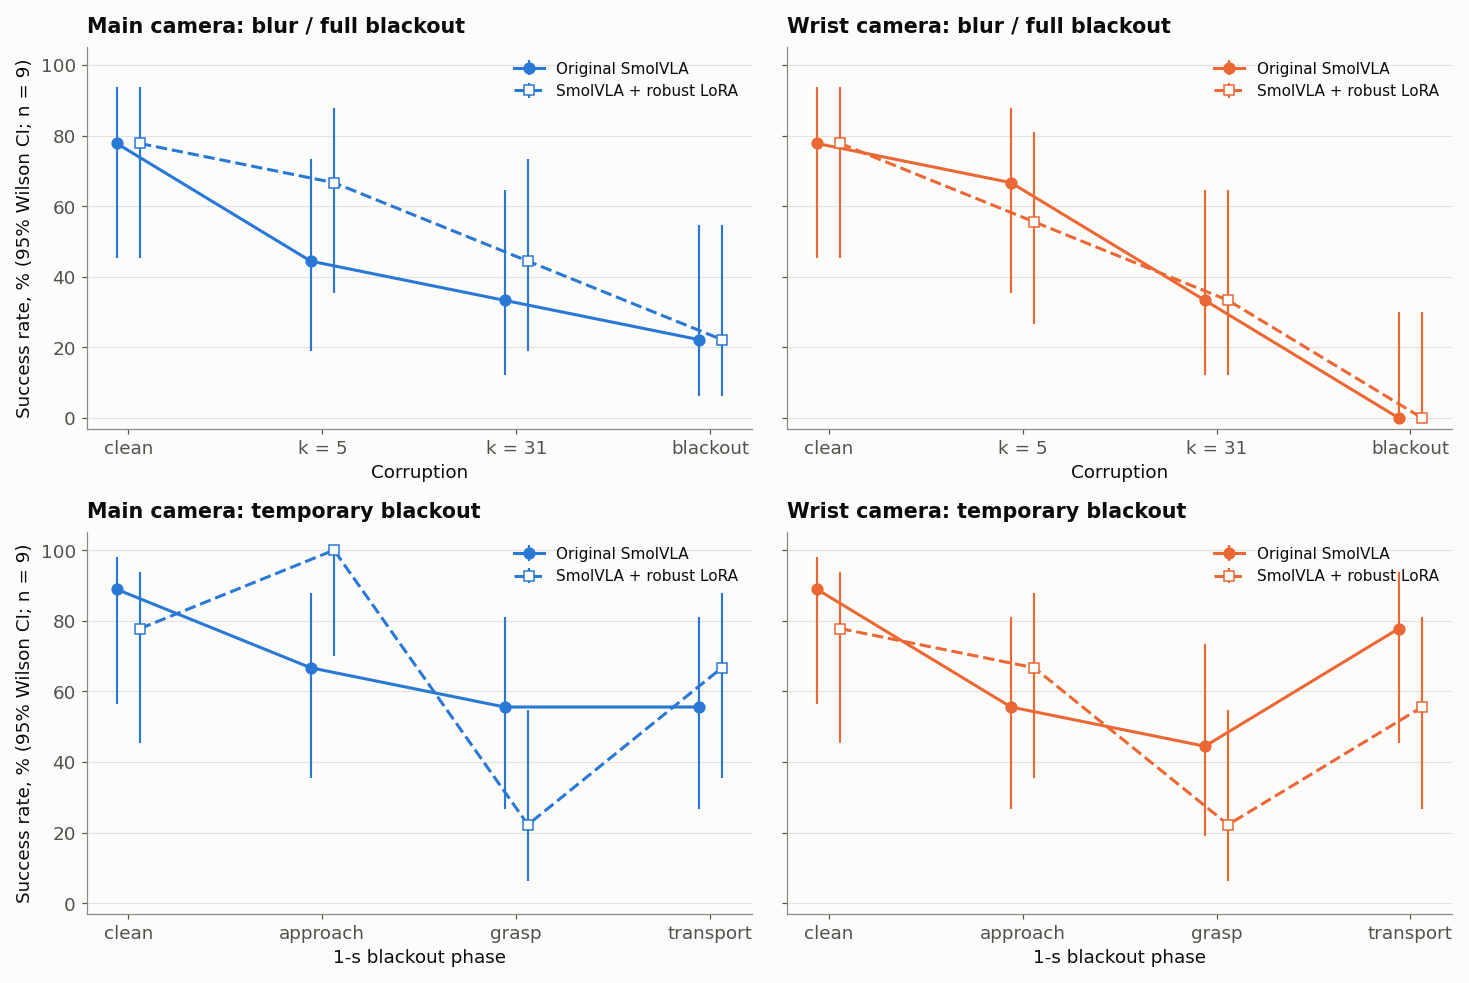

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9), sharey=True)
for row, group in enumerate(robust_groups):
    for col, camera in enumerate(["main", "wrist"]):
        ax = axes[row, col]
        conditions = (["clean", f"blur_5_{col}", f"blur_31_{col}", f"turnoff_{col}"] if row == 0
                      else ["clean"] + [f"off_{phase}_{col}" for phase in PHASES])
        labels = ["clean", "k = 5", "k = 31", "blackout"] if row == 0 else ["clean", "approach", "grasp", "transport"]
        x = np.arange(len(conditions))
        for model in ROBUST_MODELS:
            marker, linestyle, offset = ROBUST_STYLE[model]
            part = robust_rates[robust_rates.comparison.eq(group) & robust_rates.model.eq(model)].set_index("condition").loc[conditions]
            ax.errorbar(x + offset, 100 * part.rate,
                        yerr=np.maximum(0, [100 * (part.rate - part.ci_low), 100 * (part.ci_high - part.rate)]),
                        marker=marker, ls=linestyle, color=COLORS[camera], ms=7, elinewidth=1.4,
                        markerfacecolor=COLORS[camera] if model == ROBUST_MODELS[0] else SURFACE,
                        label=model)
        ax.set_xticks(x, labels)
        ax.set_ylim(-3, 105)
        ax.set_title(f"{camera.capitalize()} camera: {group}")
        ax.set_xlabel("Corruption" if row == 0 else "1-s blackout phase")
        ax.grid(axis="x", visible=False)
        ax.legend(fontsize=10)
        if col == 0:
            ax.set_ylabel("Success rate, % (95% Wilson CI; n = 9)")
fig.tight_layout()
save(fig, "robust_lora_success")
plt.show()

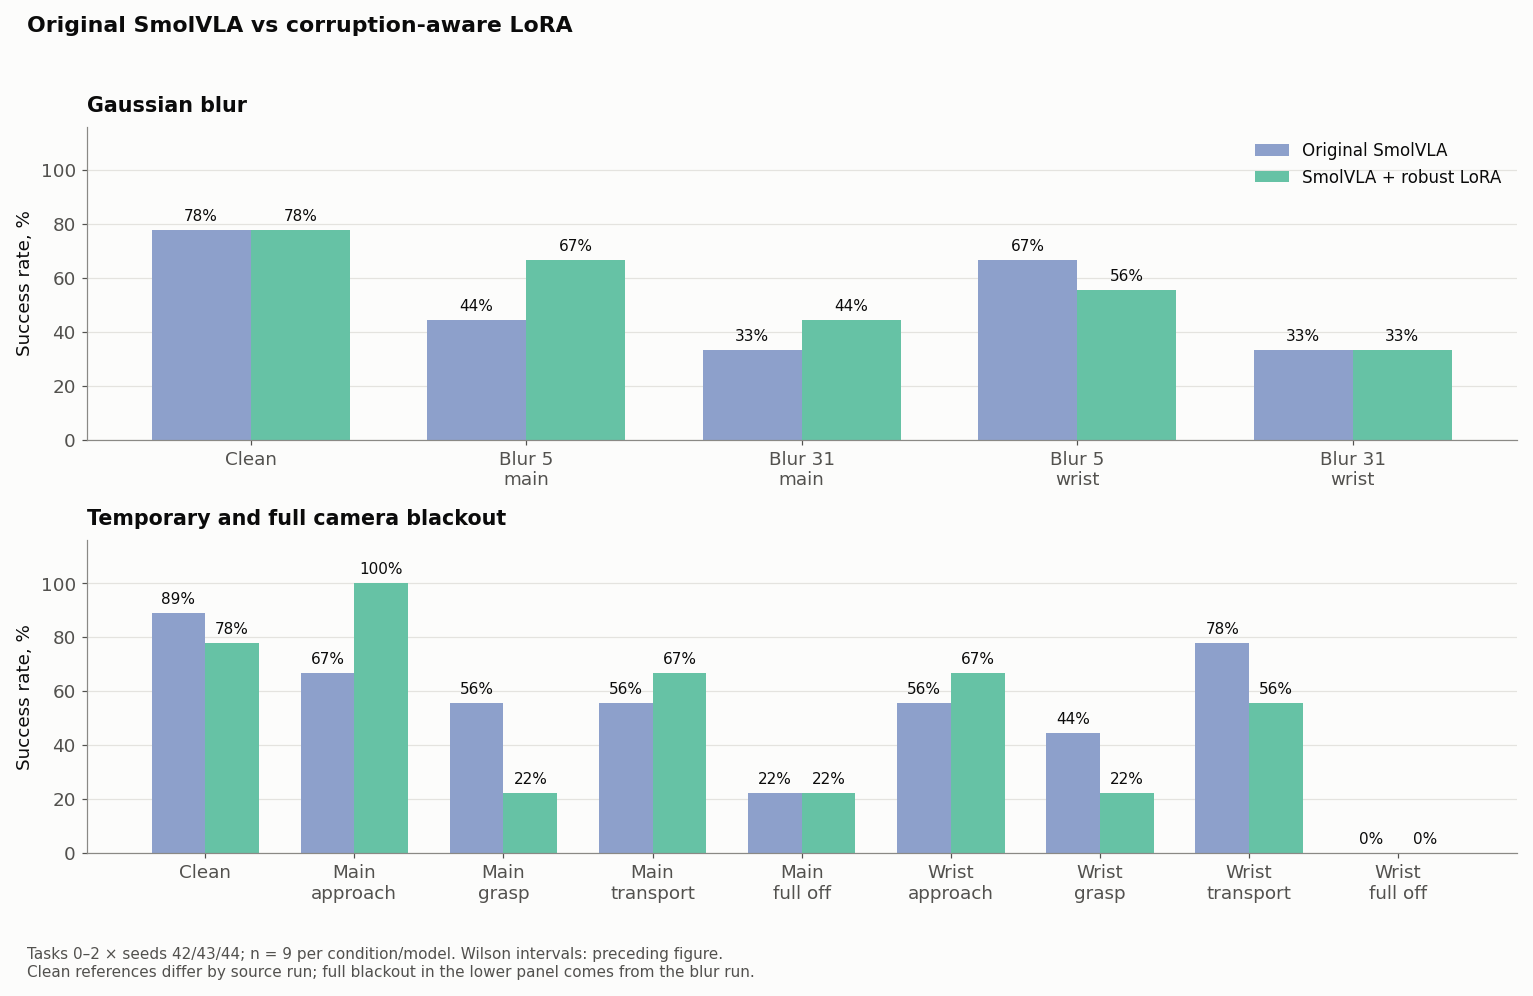

In [28]:
# Grouped bars for the two models; run after the section 11 data-loading cell.
# Colours identify models here (unlike the camera colours in the line plots).
bar_panels = [
    (["clean", "blur_5_0", "blur_31_0", "blur_5_1", "blur_31_1"],
     ["Clean", "Blur 5\nmain", "Blur 31\nmain", "Blur 5\nwrist", "Blur 31\nwrist"],
     "Gaussian blur"),
    (["clean", "off_approach_0", "off_grasp_0", "off_transport_0", "turnoff_0",
      "off_approach_1", "off_grasp_1", "off_transport_1", "turnoff_1"],
     ["Clean", "Main\napproach", "Main\ngrasp", "Main\ntransport", "Main\nfull off",
      "Wrist\napproach", "Wrist\ngrasp", "Wrist\ntransport", "Wrist\nfull off"],
     "Temporary and full camera blackout"),
]
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
bar_width = 0.36
for panel, (ax, (conditions, labels, title)) in enumerate(zip(axes, bar_panels)):
    x = np.arange(len(conditions))
    for model_index, (model, color) in enumerate(zip(ROBUST_MODELS, ["#8da0cb", "#66c2a5"])):
        # Full blackout is from the original blur run; temporary blackout and
        # its clean reference come from the dedicated temporary-off run.
        rows = []
        for condition in conditions:
            group = "blur / full blackout" if panel == 0 or condition.startswith("turnoff_") else "temporary blackout"
            rows.append(robust_rates.loc[robust_rates.model.eq(model)
                        & robust_rates.comparison.eq(group) & robust_rates.condition.eq(condition)].iloc[0])
        data = pd.DataFrame(rows)
        bars = ax.bar(x + (model_index - 0.5) * bar_width, 100 * data.rate,
                      bar_width, color=color, label=model)
        ax.bar_label(bars, labels=[f"{100 * v:.0f}%" for v in data.rate], padding=4, fontsize=10)
    ax.set(title=title, ylabel="Success rate, %", ylim=(0, 116))
    ax.set_xticks(x, labels)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
fig.suptitle("Original SmolVLA vs corruption-aware LoRA", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.01, "Tasks 0–2 × seeds 42/43/44; n = 9 per condition/model. Wilson intervals: preceding figure.\n"
         "Clean references differ by source run; full blackout in the lower panel comes from the blur run.",
         fontsize=10, color=INK_2)
fig.tight_layout(rect=(0, 0.065, 1, 0.96))
save(fig, "robust_lora_bars")
plt.show()


## 12. Does fine-tuning change the attention response?

Compare the completed controlled probes `controlled_attention/attention.csv` (original) and
`controlled_attention_lora/attention.csv` (LoRA), with **blur k = 51**, tasks 0–1, seeds 42–43,
and policy steps 0/15/30/45/60. As above, first average heads and denoising steps, then calculate
`100 · (blur / clean − 1)` separately for each model, task, seed, step and layer.

Each panel shows the last recorded layer, with means and min–max ranges over **four task/seed pairs** at each step.
Colours identify the attended camera; line styles identify the model. Clean and corrupted inputs share an observation
**within each model**. Each model drives its own clean trajectory, so later states are not identical across models:
this is a comparison of attention responses along their respective trajectories, not a same-image causal test of LoRA.
Heads and denoising steps are not treated as independent episodes.

The additional LoRA k=5/31 run exists, but its matching original controlled run is absent. The multiblur JSON plans
alone are not results, so the direct controlled comparison below uses only the common measured severity k=51.

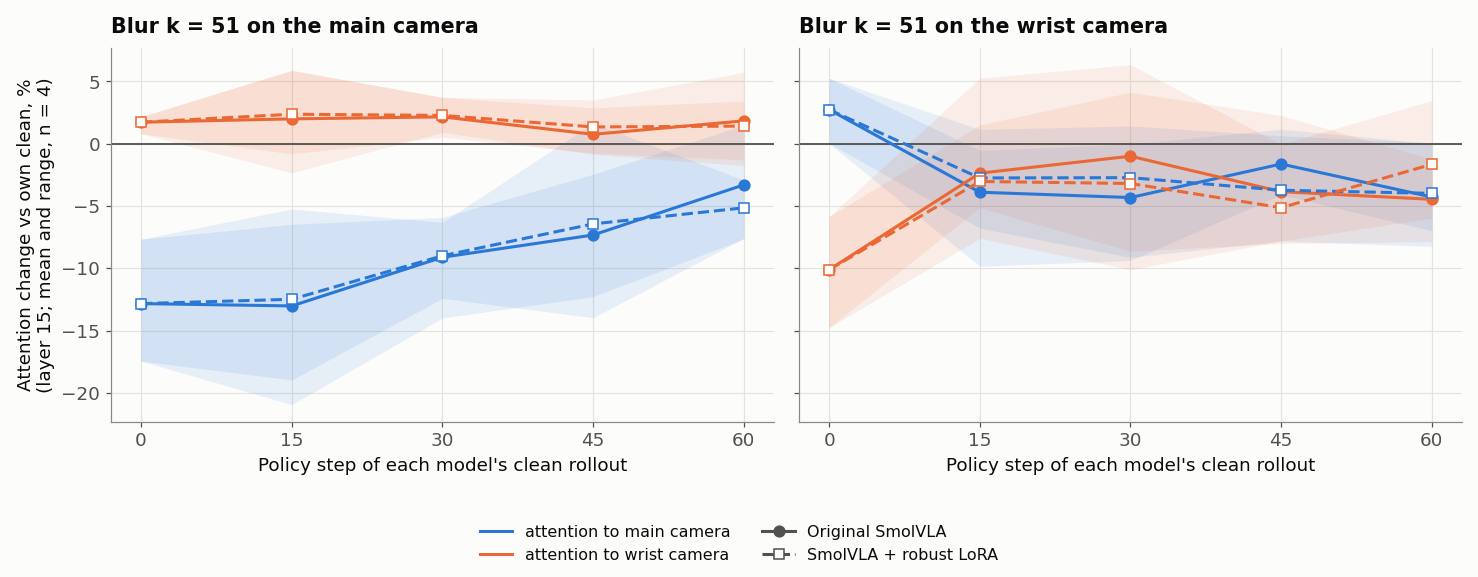

camera,model,condition,layer,rel_to_main,rel_to_wrist
0,Original SmolVLA,blur_51_0,7,-6.4%,+4.4%
1,Original SmolVLA,blur_51_0,15,-9.1%,+1.7%
2,Original SmolVLA,blur_51_1,7,+4.3%,-5.7%
3,Original SmolVLA,blur_51_1,15,-2.3%,-4.4%
4,SmolVLA + robust LoRA,blur_51_0,7,-6.3%,+4.4%
5,SmolVLA + robust LoRA,blur_51_0,15,-9.2%,+1.8%
6,SmolVLA + robust LoRA,blur_51_1,7,+4.5%,-6.9%
7,SmolVLA + robust LoRA,blur_51_1,15,-2.1%,-4.6%


In [29]:
robust_attention_frames = []
robust_attention_keys = ["task_id", "seed", "env_step", "layer"]
for model, relative_path in zip(ROBUST_MODELS, ["controlled_attention/attention.csv", "controlled_attention_lora/attention.csv"]):
    raw = pd.read_csv(RESULTS / relative_path)
    raw_keys = ["condition"] + robust_attention_keys + ["batch_index", "denoise_step", "head", "camera"]
    assert not raw.duplicated(raw_keys).any(), relative_path
    mass = camera_attention(raw, ["condition"] + robust_attention_keys)
    relative = relative_to_clean(mass, robust_attention_keys)
    assert len(relative) == len(mass), "Every measurement needs its own clean partner"
    assert np.isfinite(relative[["rel_to_main", "rel_to_wrist"]]).all().all()
    robust_attention_frames.append(relative.assign(model=model))
robust_attention = pd.concat(robust_attention_frames, ignore_index=True)
# Require the same measured design, without silently dropping unmatched rows.
measurement_keys = ["condition"] + robust_attention_keys
assert set(map(tuple, robust_attention_frames[0][measurement_keys].to_numpy())) == set(map(tuple, robust_attention_frames[1][measurement_keys].to_numpy()))
robust_layer = int(robust_attention.layer.max())
robust_attention_plot = robust_attention[robust_attention.layer.eq(robust_layer) & robust_attention.condition.ne("clean")]
assert robust_attention_plot.groupby(["model", "condition", "env_step"]).size().eq(4).all()
robust_attention_stats = robust_attention_plot.groupby(["model", "condition", "env_step"])[["rel_to_main", "rel_to_wrist"]].agg(["mean", "min", "max"])
robust_attention.to_csv(TABLES / "robust_lora_attention_paired.csv", index=False)
robust_attention_stats.to_csv(TABLES / "robust_lora_attention_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)
for ax, (condition, corrupted_camera) in zip(axes, [("blur_51_0", "main"), ("blur_51_1", "wrist")]):
    ax.axhline(0, color=INK_2, lw=1.2)
    for model in ROBUST_MODELS:
        marker, linestyle, _ = ROBUST_STYLE[model]
        part = robust_attention_stats.loc[(model, condition)]
        for camera in ["main", "wrist"]:
            column = f"rel_to_{camera}"
            ax.fill_between(part.index, part[(column, "min")], part[(column, "max")],
                            color=COLORS[camera], alpha=0.10, lw=0)
            ax.plot(part.index, part[(column, "mean")], marker=marker, ls=linestyle, color=COLORS[camera],
                    markerfacecolor=COLORS[camera] if model == ROBUST_MODELS[0] else SURFACE)
    ax.set_title(f"Blur k = 51 on the {corrupted_camera} camera")
    ax.set_xlabel("Policy step of each model's clean rollout")
    ax.set_xticks(sorted(robust_attention_plot.env_step.unique()))
axes[0].set_ylabel(f"Attention change vs own clean, %\n(layer {robust_layer}; mean and range, n = 4)")
handles = [Line2D([0], [0], color=COLORS[c], label=f"attention to {c} camera") for c in ["main", "wrist"]]
handles += [Line2D([0], [0], color=INK_2, marker=ROBUST_STYLE[m][0], ls=ROBUST_STYLE[m][1],
                   markerfacecolor=INK_2 if m == ROBUST_MODELS[0] else SURFACE, label=m) for m in ROBUST_MODELS]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=10.5)
fig.tight_layout(rect=(0, 0.13, 1, 1))
save(fig, "robust_lora_attention_controlled")
plt.show()

# Keep both recorded layers visible in the accompanying table. Average steps within
# each task/seed first; this does not turn repeated observations into new episodes.
robust_attention_by_pair = robust_attention[robust_attention.condition.ne("clean")].groupby(
    ["model", "condition", "task_id", "seed", "layer"], as_index=False)[["rel_to_main", "rel_to_wrist"]].mean()
show(robust_attention_by_pair.groupby(["model", "condition", "layer"], as_index=False)[["rel_to_main", "rel_to_wrist"]].mean(),
     {"rel_to_main": "{:+.1f}%", "rel_to_wrist": "{:+.1f}%"})